# Семинар. Как спрогнозировать два года на примере T30

В конце июня 2005 года известны 306 месяцев истории T30. Нужен прогноз на июль 2005 — июнь 2007 года. Сначала посмотрим на сезонный рисунок, затем обучим DLinear, запустим предобученный Chronos-Bolt и сравним оба прогноза с повторением последнего года.


In [ ]:
from pathlib import Path
import json
import os
import sys

os.environ.setdefault("USE_TF", "0")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import Image, display
from numpy.lib.stride_tricks import sliding_window_view
from statsmodels.tsa.seasonal import STL

from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

data_path = Path("tourism_monthly_dataset.tsf")
if not data_path.is_file():
    url = "https://zenodo.org/records/4656096/files/tourism_monthly_dataset.zip?download=1"
    with urlopen(url, timeout=90) as response, ZipFile(BytesIO(response.read())) as archive:
        data_path.write_bytes(archive.read(data_path.name))

output_dir = Path("Результаты запуска")
fig_dir = output_dir / "Графики"
fig_dir.mkdir(parents=True, exist_ok=True)
figure_output_dir = fig_dir

H, L, ALPHA = 24, 12, 1.0
models = ("seasonal", "recursive", "direct")
labels = {"seasonal": "Повтор сезона", "recursive": "Рекурсивная Ridge", "direct": "Прямые Ridge"}
colors = {"seasonal": "#147D74", "recursive": "#975D09", "direct": "#345FA1"}
styles = {"seasonal": "--", "recursive": "-.", "direct": "-"}
ink = "#172B42"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 14, "axes.labelcolor": ink,
    "text.color": ink, "xtick.color": ink, "ytick.color": ink, "axes.edgecolor": "#A7B2BC",
    "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "white",
    "savefig.facecolor": "white", "legend.frameon": False,
})

def finish(fig, filename):
    fig.savefig(fig_dir / filename, dpi=155, facecolor="white", bbox_inches="tight", pad_inches=0.12)
    plt.close(fig)
    display(Image(filename=str(fig_dir / filename), width=900))

<a id="origin"></a>

## Данные и единица наблюдения

Каждая запись в исходном файле задаёт отдельный ряд, месяц его начала и последовательность значений. Идентификаторы анонимные. У разных рядов могут различаться число наблюдений и календарная дата окончания. Один шаг соответствует одному месяцу. Последние 24 значения каждого ряда отводим для проверки.

In [2]:
lines = data_path.read_text(encoding="cp1252").splitlines()
rows = lines[lines.index("@data") + 1:]
series = {}
for row in rows:
    if not row.strip() or row.startswith("#"):
        continue
    name, start, values_text = row.split(":")
    values = np.array([float(value) for value in values_text.split(",")])
    dates = pd.date_range(start=start.split()[0], periods=len(values), freq="MS")
    series[name] = pd.Series(values, index=dates, name=name)
assert len(series) == 366 and all(np.isfinite(y).all() for y in series.values())
lengths = [len(y) for y in series.values()]
print(f"{len(series)} рядов. Длина от {min(lengths)} до {max(lengths)} месяцев.")

366 рядов. Длина от 91 до 333 месяцев.


In [3]:
t30_train = series["T30"].iloc[:-H]
t30_test = series["T30"].iloc[-H:]
assert (len(t30_train), len(t30_test)) == (306, 24)
display(pd.DataFrame({
    "С какого месяца": [t30_train.index[0], t30_test.index[0]],
    "По какой месяц": [t30_train.index[-1], t30_test.index[-1]],
    "Число наблюдений": [len(t30_train), len(t30_test)],
}, index=["Известная история", "Будущие месяцы для оценки"]))

,С какого месяца,По какой месяц,Число наблюдений
Известная история,1980-01-01,2005-06-01,306
Будущие месяцы для оценки,2005-07-01,2007-06-01,24


<a id="first-errors"></a>

### Как читать ошибку прогноза

В конце июня 2005 года спрогнозируем июль, август и сентябрь по тем же месяцам 2004 года. Теперь откроем факты и положим $e=y-\hat y$. Положительная ошибка означает, что прогноз занизил значение. При усреднении знаки могут компенсироваться, поэтому для MAE берём модули. Последний столбец показывает модуль ошибки как процент от факта соответствующего месяца.

In [4]:
first_dates = t30_test.index[:3]
prior_dates = first_dates - pd.DateOffset(years=1)
first_forecast = t30_train.loc[prior_dates].to_numpy()
first_actual = t30_test.loc[first_dates].to_numpy()
first_error = first_actual - first_forecast
first_abs = np.abs(first_error)

first_table = pd.DataFrame({
    "Факт": first_actual,
    "Сезонный прогноз": first_forecast,
    "Ошибка": first_error,
    "|Ошибка|": first_abs,
    "APE, %": 100 * first_abs / np.abs(first_actual),
}, index=first_dates.strftime("%Y-%m"))
display(first_table.round(2))
print(f"MAE за эти три месяца: {first_abs.mean():.2f}")
print(f"MAPE за эти три месяца: {first_table['APE, %'].mean():.2f} %")

,Факт,Сезонный прогноз,Ошибка,|Ошибка|,"APE, %"
2005-07,46251.0,44964.0,1287.0,1287.0,2.78
2005-08,34231.0,34524.0,-293.0,293.0,0.86
2005-09,27243.0,26396.0,847.0,847.0,3.11


MAE за эти три месяца: 809.00
MAPE за эти три месяца: 2.25 %


В июле прогноз 44 964, факт 46 251. Недооценка составила 1 287 единиц, или 2,78% июльского факта. В августе прогноз оказался выше факта на 293 единицы. В MAE за три месяца входят числа 1 287, 293 и 847.

### История до июня 2005 года

Покажем последние десять лет известной истории. Где повторяются годовые пики? Меняется ли уровень, вокруг которого они колеблются?

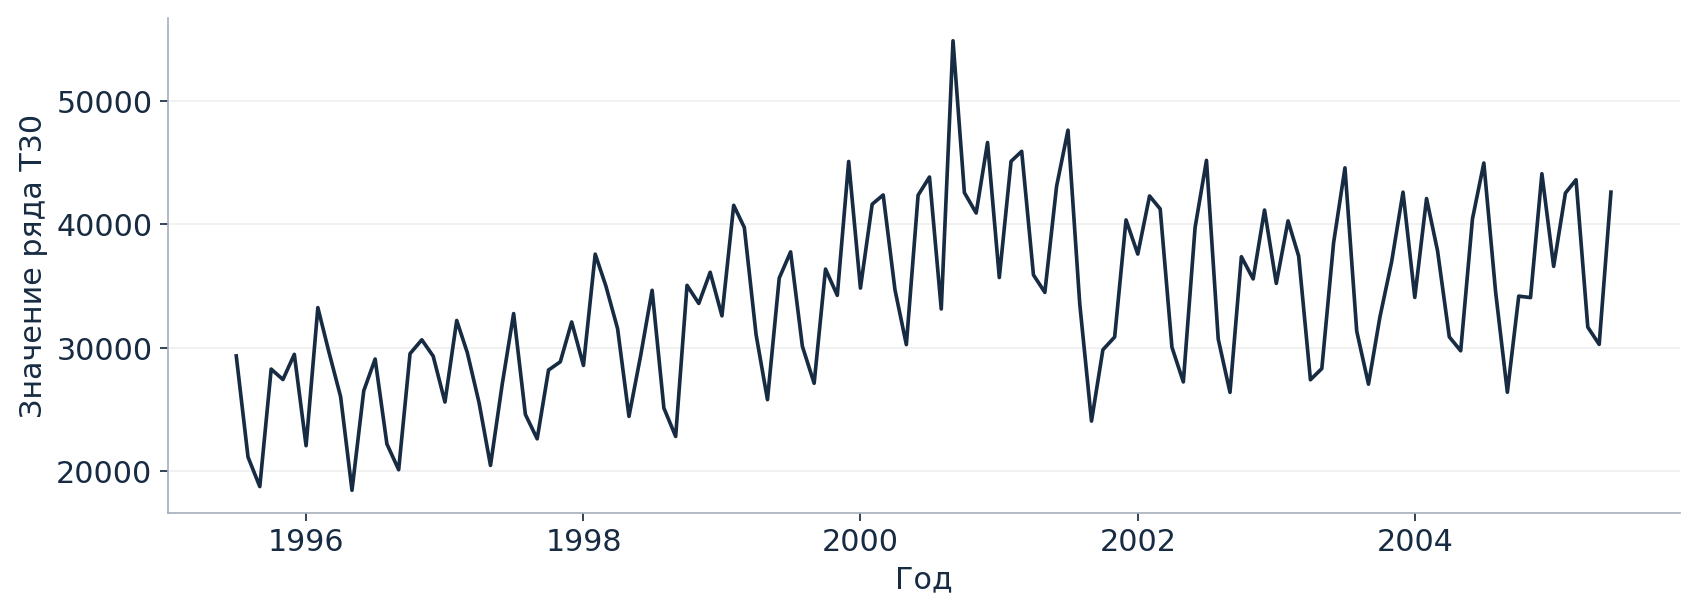

In [5]:
history = t30_train.iloc[-120:]
fig, ax = plt.subplots(figsize=(10.8, 3.8), layout="constrained")
ax.plot(history.index, history, color=ink, linewidth=1.7)
ax.set(xlabel="Год", ylabel="Значение ряда T30")
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(axis="y", alpha=0.2)
finish(fig, "01_series_T30.png")

### Сезонный профиль T30

Один и тот же месяц можно сравнить в разные годы, даже если общий уровень ряда менялся. Берём полные календарные годы из истории до выпуска. В каждом году делим месячные значения на среднее за этот год и умножаем на 100. Теперь 100 означает обычный для данного года месяц. На графике линия показывает медиану по годам, полоса — интервал между первым и третьим квартилями.

В таблице сравним февраль и май. Их медианы равны примерно 117% и 75% среднего месяца своего года.

,"Первый квартиль, %","Медиана, %","Третий квартиль, %"
Февраль,108.3,116.6,120.6
Май,73.2,74.5,82.4


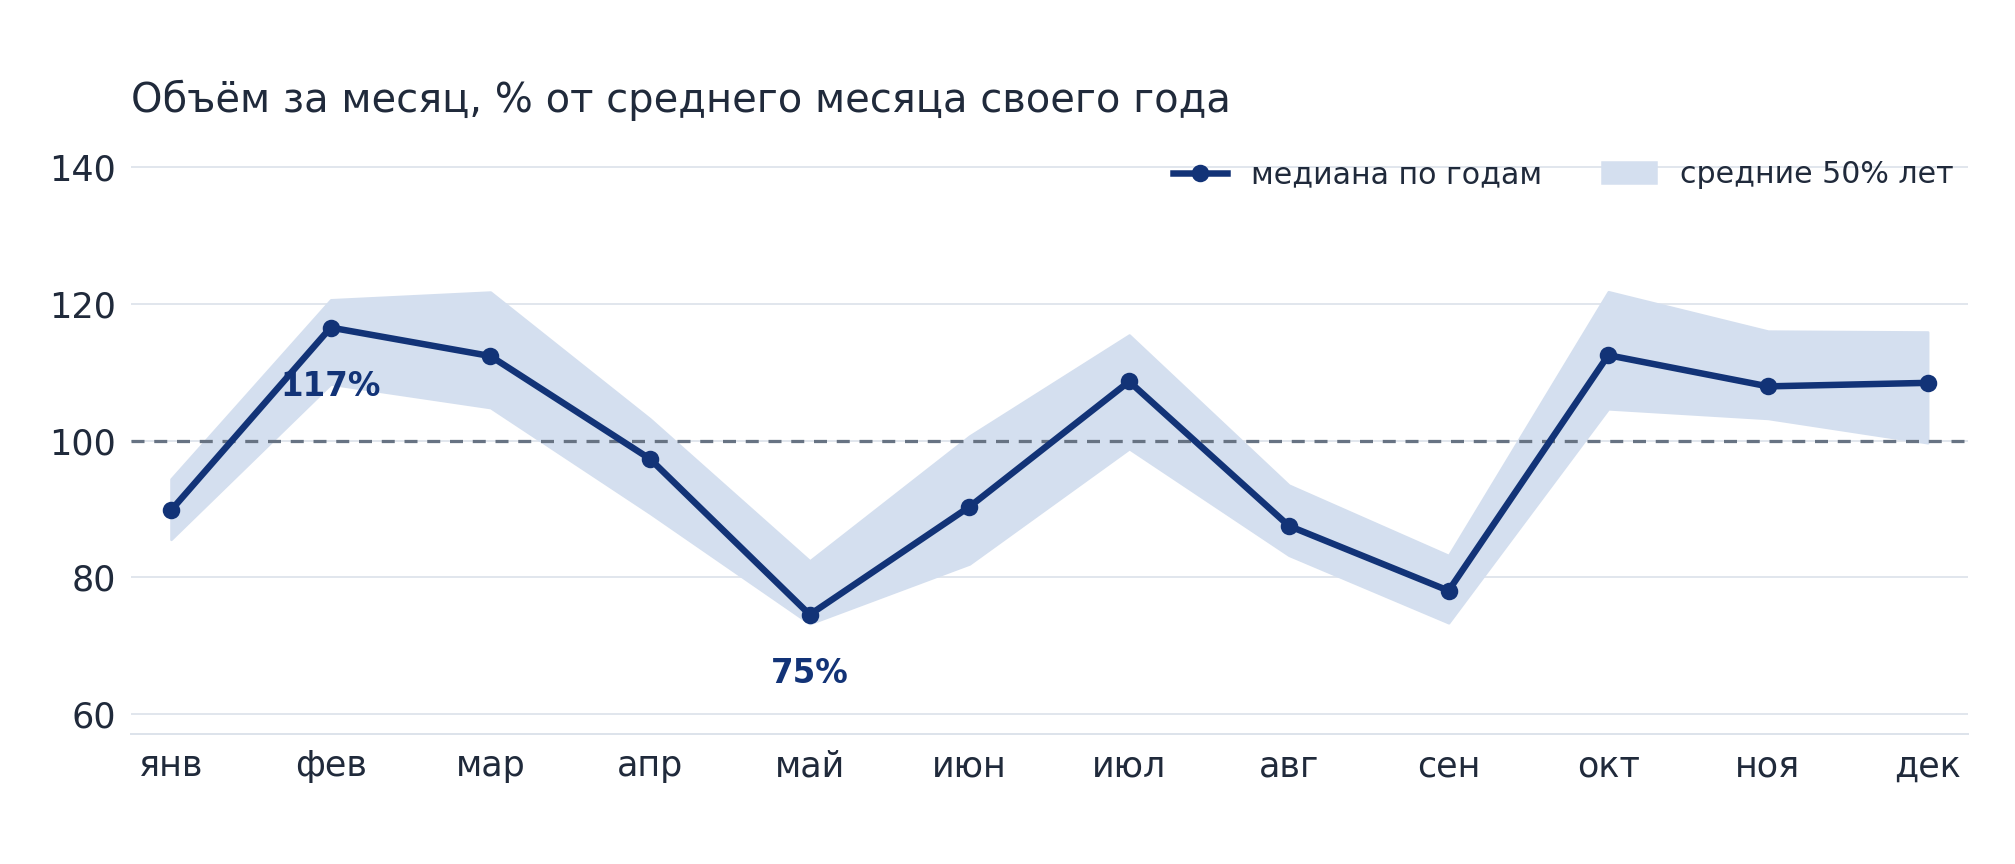

In [6]:
def _tourism_diagnostics_functions():
    from pathlib import Path

    import matplotlib.dates as mdates

    import matplotlib.pyplot as plt

    import numpy as np

    import pandas as pd

    from statsmodels.tsa.stattools import acf

    HERE = Path.cwd()

    DATASET = data_path

    SERIES_ID = "T30"

    HORIZON = 24

    BLUE = "#123377"

    ORANGE = "#B9571A"

    DARK = "#202A3B"

    GRAY = "#677383"

    LIGHT = "#DDE3EB"

    MONTHS = ["янв", "фев", "мар", "апр", "май", "июн", "июл", "авг", "сен", "окт", "ноя", "дек"]

    def save_png(fig, destination):
        path = Path(destination)
        try:
            path.parent.mkdir(parents=True, exist_ok=True)
            fig.savefig(path, facecolor="white")
        finally:
            plt.close(fig)
        return path

    def style_axes(ax):
        ax.spines[["left", "top", "right"]].set_visible(False)
        ax.spines["bottom"].set_color(LIGHT)
        ax.yaxis.grid(True, color=LIGHT, lw=0.7)
        ax.set_axisbelow(True)
        ax.tick_params(length=0, pad=6, colors=DARK)

    PLOT_STYLE = {
        "font.family": "DejaVu Sans", "font.size": 14, "axes.titlesize": 16,
        "axes.labelsize": 13, "text.color": DARK, "axes.labelcolor": DARK,
        "axes.titlecolor": DARK, "savefig.dpi": 180,
    }

    def monthly_relative_profile(history):
        """Квартили относительных объёмов по месяцам на полных годах истории."""
        # Нормирование по полному календарному году нужно лишь для описания истории.
        sizes = history.groupby(history.index.year).transform("size")
        full_years = history.loc[sizes == 12]
        normalized = 100 * full_years / full_years.groupby(full_years.index.year).transform("mean")
        profile = normalized.groupby(normalized.index.month).quantile([0.25, 0.5, 0.75]).unstack()
        return profile

    @plt.style.context(["default", PLOT_STYLE])
    def seasonal_profile(history, destination=HERE / "components.png"):
        """Сохранить на диск сезонный профиль и вернуть путь к PNG."""
        profile = monthly_relative_profile(history)
        months = profile.index

        fig, ax = plt.subplots(figsize=(11.2, 4.8))
        fig.subplots_adjust(left=0.065, right=0.976, top=0.83, bottom=0.15)
        style_axes(ax)
        ax.set_title("Объём за месяц, % от среднего месяца своего года", loc="left", pad=14)
        ax.fill_between(months, profile[0.25], profile[0.75], color="#D4DFEF", label="средние 50% лет")
        ax.plot(months, profile[0.5], color=BLUE, lw=2.6, marker="o", ms=6, label="медиана по годам")
        ax.axhline(100, color=GRAY, lw=1.3, ls=(0, (4, 3)), zorder=1)
        for m, dy in [(2, -17), (5, -17)]:
            value = profile.loc[m, 0.5]
            ax.annotate(f"{value:.0f}%", (m, value), xytext=(0, dy), textcoords="offset points",
                        ha="center", va="top", fontsize=13, color=BLUE, weight="bold")
        ax.set(xticks=months, xticklabels=MONTHS, yticks=[60, 80, 100, 120, 140],
               xlim=(0.75, 12.25), ylim=(57, 143))
        handles, labels = ax.get_legend_handles_labels()
        ax.legend(handles[::-1], labels[::-1], loc="upper right", ncol=2, frameon=False,
                  handlelength=1.8, fontsize=12, borderaxespad=0.05)
        return save_png(fig, destination)

    def acf_by_lag(history, max_lag=30):
        """ACF значений и годовых разностей. В индексе таблицы — лаг в месяцах."""
        values = {"Исходный ряд": history, "После сезонной разности": history.diff(12).dropna()}
        return pd.DataFrame(
            {name: acf(row, nlags=max_lag, fft=False, adjusted=False)[1:] for name, row in values.items()},
            index=pd.RangeIndex(1, max_lag + 1, name="Лаг, месяцы"),
        )

    @plt.style.context(["default", PLOT_STYLE])
    def lag_correlations(history, destination=HERE / "acf.png"):
        """Сохранить ACF исходного ряда и сезонных разностей; вернуть путь к PNG."""
        correlations = acf_by_lag(history)
        fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.8), sharey=True)
        fig.subplots_adjust(left=0.07, right=0.98, top=0.79, bottom=0.20, wspace=0.15)
        fig.text(0.07, 0.955, "Выборочная автокорреляция", fontsize=17, color=DARK, va="top")
        lags = correlations.index.to_numpy()
        for ax, (title, column) in zip(axes, correlations.items()):
            coefs = column.to_numpy()
            style_axes(ax)
            ax.axhline(0, color=GRAY, lw=1.1)
            ax.vlines(lags, 0, coefs, color=BLUE, lw=2.0, alpha=0.8)
            ax.scatter(lags, coefs, color=BLUE, s=13, zorder=2)
            for lag in [12, 24]:
                value = coefs[lag - 1]
                ax.vlines(lag, 0, value, color=ORANGE, lw=2.4)
                ax.scatter([lag], [value], color=ORANGE, s=26, zorder=3)
                label = f"{value:.2f}".replace(".", ",").replace("-", "−")
                dy = 7 if value > 0 else -7
                ax.annotate(label, (lag, value), xytext=(0, dy), textcoords="offset points", ha="center",
                            va="bottom" if value > 0 else "top", color=ORANGE, fontsize=12, weight="bold")
            ax.set_title(title, loc="left", pad=11, fontsize=15)
            ax.set(xlim=(0, 31), ylim=(-0.40, 1.06), xticks=[1, 6, 12, 18, 24, 30],
                   yticks=[-0.25, 0, 0.25, 0.50, 0.75, 1.0], xlabel="Лаг, месяцы")
            ax.tick_params(labelsize=12)
        axes[0].set_yticklabels(["−0,25", "0", "0,25", "0,50", "0,75", "1"])
        return save_png(fig, destination)

    return monthly_relative_profile, seasonal_profile, acf_by_lag, lag_correlations

monthly_relative_profile, seasonal_profile, acf_by_lag, lag_correlations = _tourism_diagnostics_functions()

month_summary = monthly_relative_profile(t30_train).loc[[2, 5]]
month_summary = month_summary.rename(
    index={2: "Февраль", 5: "Май"},
    columns={0.25: "Первый квартиль, %", 0.5: "Медиана, %", 0.75: "Третий квартиль, %"},
)
display(month_summary.round(1))
seasonal_png = seasonal_profile(t30_train, figure_output_dir / "components.png")
display(Image(filename=str(seasonal_png), width=900))

### STL на истории до отсечки

Разложим T30 на тренд, сезонную часть и остаток с периодом 12. На отдельных осях видны и медленное движение уровня, и колебания внутри года. Позже сравним этот способ описания истории со сглаживанием внутри DLinear.

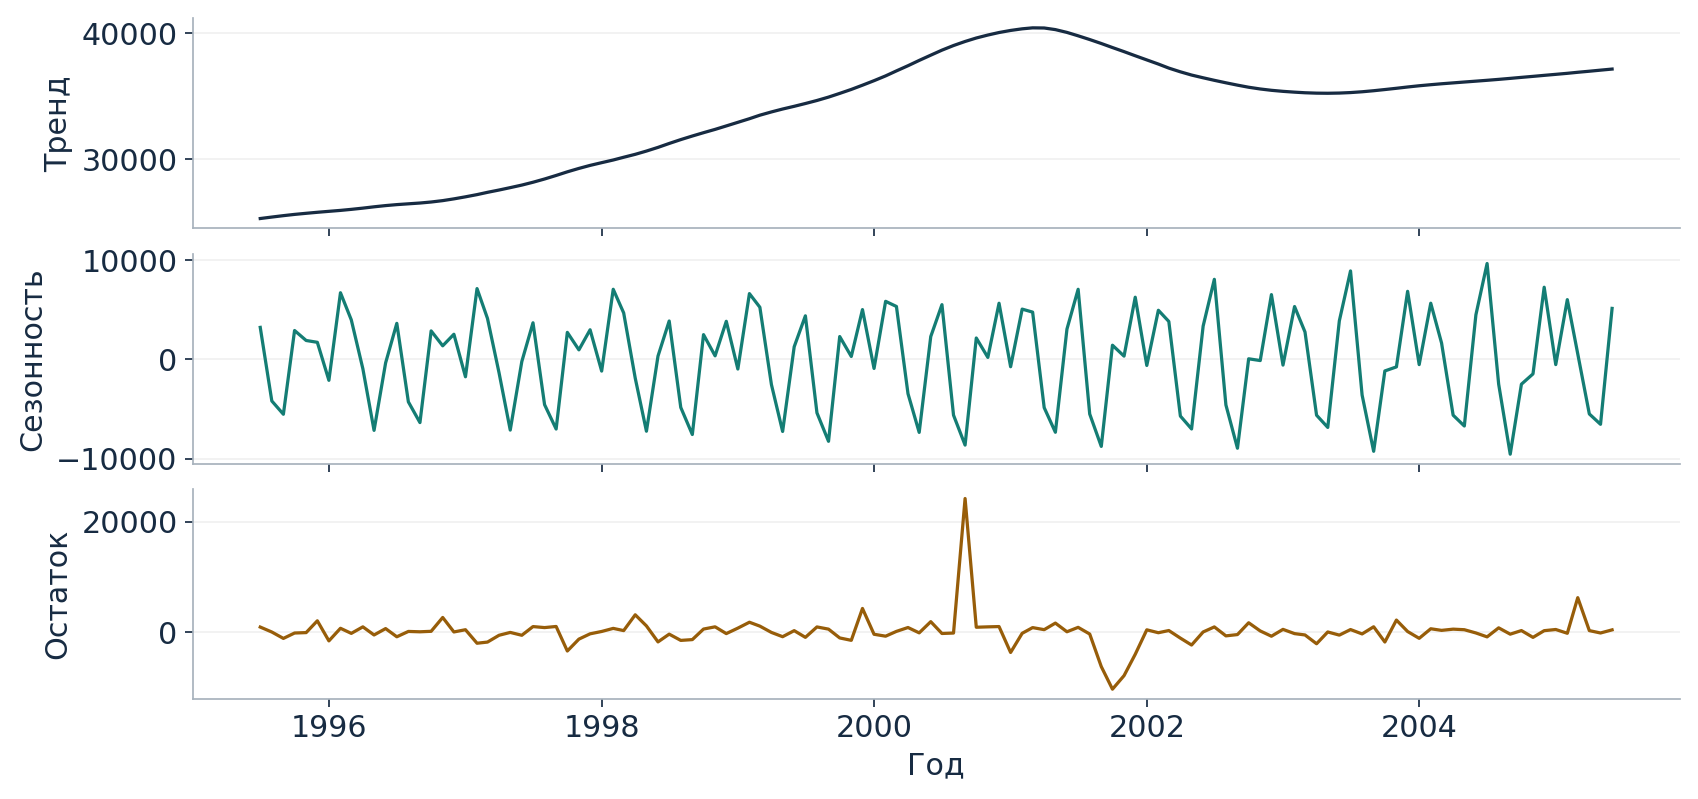

In [7]:
stl = STL(t30_train, period=12, robust=True).fit()
components = {"Тренд": stl.trend, "Сезонность": stl.seasonal, "Остаток": stl.resid}
fig, axes = plt.subplots(3, 1, sharex=True, figsize=(10.8, 5), layout="constrained")
for ax, (label, component), color in zip(axes, components.items(), (ink, colors["seasonal"], colors["recursive"])):
    view = component.iloc[-120:]
    ax.plot(view.index, view, color=color, linewidth=1.5)
    ax.set_ylabel(label)
    ax.grid(axis="y", alpha=0.18)
axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[-1].set_xlabel("Год")
finish(fig, "02_stl_T30.png")

### Автокорреляция до и после сезонной разности

На графике слева исходный T30, справа разности $y_t-y_{t-12}$. Столбик на лаге 12 показывает выборочную автокорреляцию через год. Сопоставим её на лагах 12 и 24, используя для обеих панелей ту же историю, что и на графике.

На лаге 12 автокорреляция исходных значений около $0{,}82$, а после годовой разности около $-0{,}21$. Сильная положительная связь ослабла и изменила знак. Одного такого сравнения недостаточно, чтобы установить стационарность ряда.

,Исходный ряд,После сезонной разности
"Лаг, месяцы",,
12,0.822,-0.209
24,0.679,-0.057


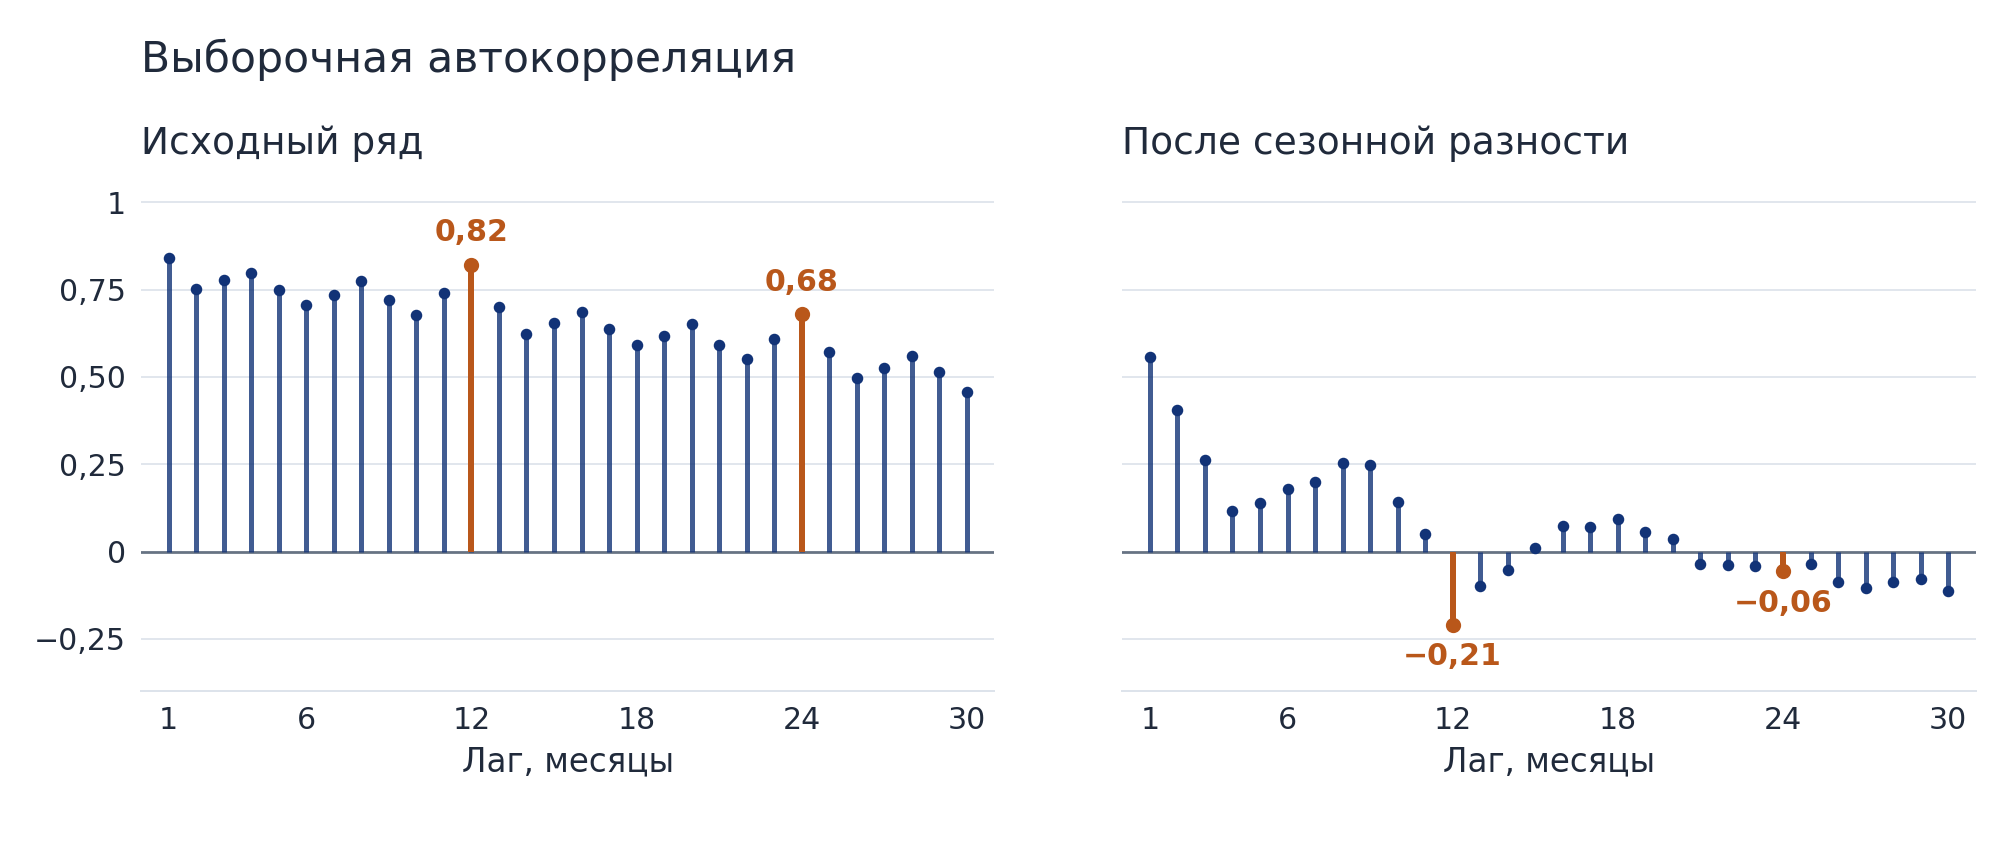

In [8]:


acf_table = acf_by_lag(t30_train)
display(acf_table.loc[[12, 24]].round(3))
acf_png = lag_correlations(t30_train, figure_output_dir / "acf.png")
display(Image(filename=str(acf_png), width=900))

### Сезонный ориентир

Если летний рисунок повторится, каждый будущий месяц получит значение того же месяца из последнего известного года. Для горизонта в два года этот год повторяется дважды. Ниже первые три значения, которые менеджер получил бы в июне 2005-го.

In [9]:
seasonal_t30 = pd.Series(np.resize(t30_train.iloc[-12:].to_numpy(), H),
                         index=t30_test.index, name="Сезонный повтор")
display(seasonal_t30.head(3).to_frame())

,Сезонный повтор
2005-07-01,44964.0
2005-08-01,34524.0
2005-09-01,26396.0


<a id="dlinear"></a>

## DLinear на T30

Из последних 48 известных значений DLinear строит сразу 24 прогноза. Модель разделяет входное окно на сглаженную часть и остаток. У каждой части своя линейная проекция из 48 чисел в 24. Для каждого горизонта модель складывает два полученных значения.

Обучим DLinear на истории T30. Каждое окно содержит 48 месяцев, прогноз охватывает следующие 24. Последние 24 факта используем для оценки.

[Статья DLinear](https://arxiv.org/abs/2205.13504) · [Реализация авторов](https://github.com/cure-lab/LTSF-Linear/blob/main/models/DLinear.py)

### Что входит в обучающий пример

Каждый пример состоит из 48 входных месяцев и следующих за ними 24 целевых. Обе части помещаются внутрь истории до конца июня 2005 года. Среднее и стандартное отклонение для обучения и будущего прогноза считаем по этой же истории. Скользящие окна перекрываются.

In [10]:
import torch
from torch import nn

dl_context = 48
dl_horizon = 24
assert H == dl_horizon
dl_train = torch.tensor(t30_train.to_numpy(), dtype=torch.float64, device="cpu")
dl_mean = dl_train.mean()
dl_std = dl_train.std(unbiased=False)
assert dl_std > 0

dl_train_z = (dl_train - dl_mean) / dl_std
dl_windows = dl_train_z.unfold(0, dl_context + dl_horizon, 1)
dl_X = dl_windows[:, :dl_context].contiguous()
dl_Y = dl_windows[:, dl_context:].contiguous()

print(f"Обучающих окон: {len(dl_X)}. Формы входа и ответа: {tuple(dl_X.shape)}, {tuple(dl_Y.shape)}.")
dl_edges = []
for dl_start in (0, len(dl_X) - 1):
    dl_dates = t30_train.index[dl_start:dl_start + dl_context + dl_horizon]
    dl_edges.append([dl_dates[0], dl_dates[dl_context - 1], dl_dates[dl_context], dl_dates[-1]])
display(pd.DataFrame(dl_edges, index=["Первое окно", "Последнее окно"],
                     columns=["Начало входа", "Конец входа", "Начало цели", "Конец цели"]))

Обучающих окон: 235. Формы входа и ответа: (235, 48), (235, 24).


,Начало входа,Конец входа,Начало цели,Конец цели
Первое окно,1980-01-01,1983-12-01,1984-01-01,1985-12-01
Последнее окно,1999-07-01,2003-06-01,2003-07-01,2005-06-01


### Две ветви модели

Скользящее среднее использует 25 точек. По краям окна недостающие позиции занимают копии ближайшего наблюдения: 12 слева и 12 справа. Поэтому сглаживание не смотрит за дату выпуска прогноза. Остаток равен разности исходного значения и сглаженного. В него могут входить сезонность, шум и другие колебания.

Два слоя `Linear(48, 24)` получают сглаженный ряд и остаток. В начале все веса равны $1/48$, оба смещения равны нулю. Сумма голов тогда повторяет среднее входного окна на каждом горизонте. Дальше веса подбираются по ошибке прогноза.

In [11]:
class DLinearT30(nn.Module):
    def __init__(self, context, horizon):
        super().__init__()
        self.pad = nn.ReplicationPad1d(12)
        self.average = nn.AvgPool1d(kernel_size=25, stride=1)
        self.trend_head = nn.Linear(context, horizon, device="cpu", dtype=torch.float64)
        self.residual_head = nn.Linear(context, horizon, device="cpu", dtype=torch.float64)
        for head in (self.trend_head, self.residual_head):
            nn.init.constant_(head.weight, 1 / context)
            nn.init.zeros_(head.bias)

    def decompose(self, x):
        # AvgPool1d ожидает оси «примеры, каналы, время». Здесь канал один.
        trend = self.average(self.pad(x.unsqueeze(1))).squeeze(1)
        return trend, x - trend

    def forward(self, x):
        trend, residual = self.decompose(x)
        return self.trend_head(trend) + self.residual_head(residual)


dl_model = DLinearT30(dl_context, dl_horizon)
with torch.no_grad():
    dl_initial = dl_model(dl_X[:1])
    torch.testing.assert_close(dl_initial, dl_X[:1].mean().expand_as(dl_initial))
print(f"Пакет из трёх окон: {tuple(dl_X[:3].shape)} → {tuple(dl_model(dl_X[:3]).shape)}")

Пакет из трёх окон: (3, 48) → (3, 24)


### Разложение последнего известного окна

На рисунке обе компоненты выражены в исходных единицах T30. Их сумма по месяцам восстанавливает вход. При стандартизации $z=(x-\mu)/\sigma$ сглаженная часть превращается в $(m-\mu)/\sigma$, а остаток — в $r/\sigma$. Это можно проверить непосредственно на тензорах.

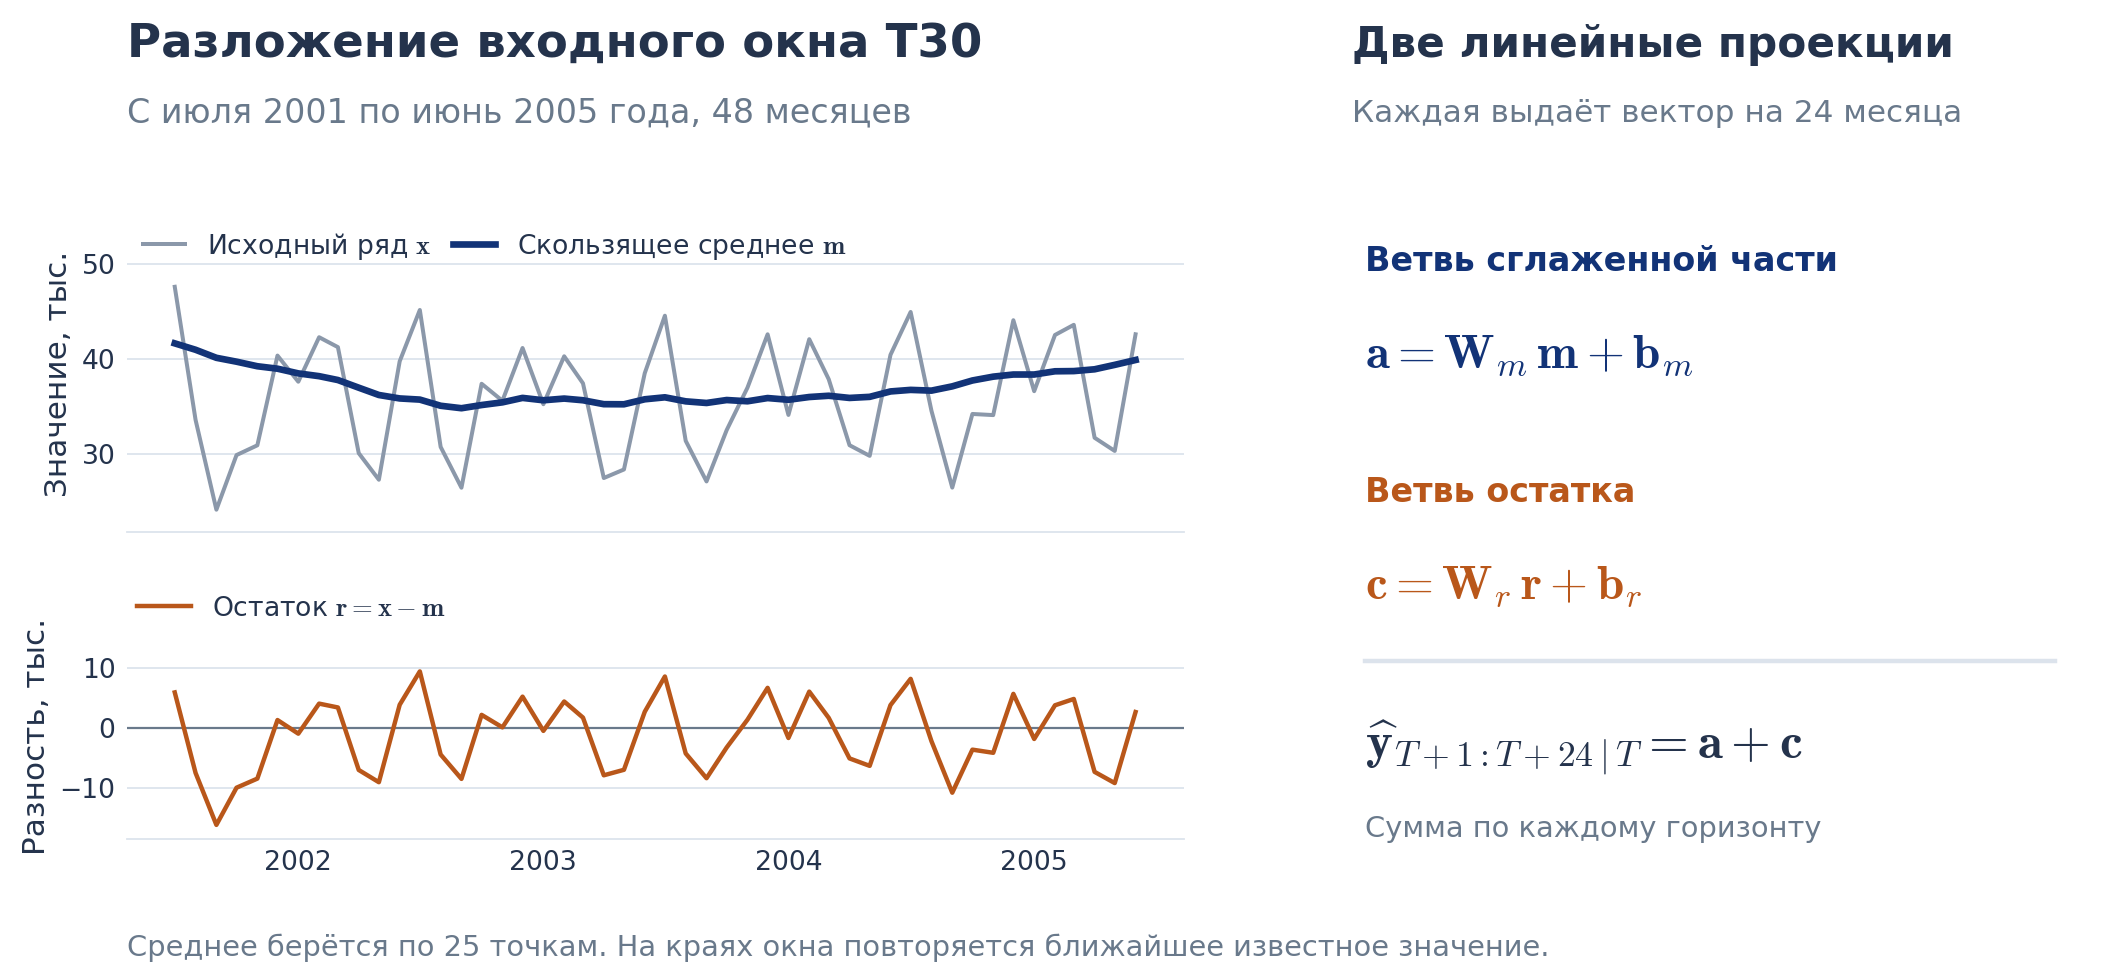

In [12]:
def _dlinear_tourism_functions():
    from pathlib import Path

    import matplotlib

    import matplotlib.dates as mdates

    import matplotlib.pyplot as plt

    import numpy as np

    import pandas as pd

    OUT = Path.cwd()

    DATA = data_path

    CONTEXT, HORIZON, KERNEL = 48, 24, 25

    BLUE, ORANGE = "#123377", "#B9571A"

    NAVY, GRAY, GRID = "#24334C", "#69798B", "#DCE3EC"

    def style_axis(ax):
        ax.spines[["top", "left", "right"]].set_visible(False)
        ax.spines["bottom"].set_color(GRID)
        ax.tick_params(length=0, pad=5, colors=NAVY, labelsize=12)
        ax.grid(axis="y", color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)

    def render_decomposition(dates, x, trend, residual, destination):
        """Draw the two components of the T30 window, supplied in the original units."""
        with plt.rc_context():
            plt.rcdefaults()
            return _draw_decomposition(dates, np.asarray(x) / 1_000, np.asarray(trend) / 1_000,
                                       np.asarray(residual) / 1_000, destination)

    def _draw_decomposition(dates, x, trend, residual, destination):
        plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 14, "text.color": NAVY,
                             "axes.labelcolor": NAVY, "mathtext.fontset": "cm"})
        fig = plt.figure(figsize=(13.2, 6.1), facecolor="white")
        gs = fig.add_gridspec(2, 2, width_ratios=[1.44, 1], height_ratios=[1.55, 1],
                              left=0.06, right=0.98, top=0.78, bottom=0.14, hspace=0.39, wspace=0.17)
        top = fig.add_subplot(gs[0, 0])
        bottom = fig.add_subplot(gs[1, 0], sharex=top)
        diagram = fig.add_subplot(gs[:, 1])
        diagram.axis("off")

        fig.text(0.06, 0.942, "Разложение входного окна T30", fontsize=21, weight="bold", color=NAVY)
        fig.text(0.06, 0.875, "С июля 2001 по июнь 2005 года, 48 месяцев", fontsize=15, color=GRAY)
        top.plot(dates, x, color="#8B98AA", lw=1.8, label=r"Исходный ряд $\mathbf{x}$")
        top.plot(dates, trend, color=BLUE, lw=3.0, label=r"Скользящее среднее $\mathbf{m}$")
        top.legend(loc="upper left", fontsize=12, frameon=False, ncol=2,
                   columnspacing=0.8, handlelength=1.6, borderaxespad=0.2)
        top.set_ylim(x.min() * 0.9, x.max() * 1.16)
        top.set_ylabel("Значение, тыс.")
        top.tick_params(axis="x", labelbottom=False)
        style_axis(top)

        bottom.axhline(0, color=GRAY, lw=1)
        bottom.plot(dates, residual, color=ORANGE, lw=2,
                    label=r"Остаток $\mathbf{r}=\mathbf{x}-\mathbf{m}$")
        bottom.legend(loc="lower left", bbox_to_anchor=(0, 1.01), fontsize=12,
                      frameon=False, borderaxespad=0.0)
        bottom.set_ylim(residual.min() * 1.15, residual.max() * 1.65)
        bottom.set_ylabel("Разность, тыс.")
        bottom.xaxis.set_major_locator(mdates.YearLocator())
        bottom.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
        style_axis(bottom)

        fig.text(0.64, 0.942, "Две линейные проекции", fontsize=19, weight="bold")
        fig.text(0.64, 0.875, "Каждая выдаёт вектор на 24 месяца", fontsize=14, color=GRAY)
        diagram.text(0.04, 0.91, "Ветвь сглаженной части", color=BLUE, fontsize=15, weight="bold")
        diagram.text(0.04, 0.755, r"$\mathbf{a}=\mathbf{W}_m\,\mathbf{m}+\mathbf{b}_m$",
                     color=BLUE, fontsize=22)
        diagram.text(0.04, 0.54, "Ветвь остатка", color=ORANGE, fontsize=15, weight="bold")
        diagram.text(0.04, 0.385, r"$\mathbf{c}=\mathbf{W}_r\,\mathbf{r}+\mathbf{b}_r$",
                     color=ORANGE, fontsize=22)
        diagram.plot([0.04, 0.98], [0.285, 0.285], color=GRID, lw=2)
        diagram.text(0.04, 0.13, r"$\widehat{\mathbf{y}}_{T+1:T+24\mid T}=\mathbf{a}+\mathbf{c}$",
                     color=NAVY, fontsize=23)
        diagram.text(0.04, 0.004, "Сумма по каждому горизонту", color=GRAY, fontsize=13)
        diagram.set(xlim=(0, 1), ylim=(0, 1))

        fig.text(0.06, 0.020, "Среднее берётся по 25 точкам. На краях окна повторяется ближайшее известное значение.",
                 fontsize=13, color=GRAY)
        fig.savefig(destination, dpi=160, facecolor="white")
        return fig

    return render_decomposition

render_decomposition = _dlinear_tourism_functions()

dl_last_dates = t30_train.index[-dl_context:]
dl_x = dl_train[-dl_context:].unsqueeze(0)
with torch.no_grad():
    dl_m, dl_r = dl_model.decompose(dl_x)
    dl_m_z, dl_r_z = dl_model.decompose((dl_x - dl_mean) / dl_std)
    torch.testing.assert_close(dl_m + dl_r, dl_x)
    torch.testing.assert_close(dl_m_z, (dl_m - dl_mean) / dl_std)
    torch.testing.assert_close(dl_r_z, dl_r / dl_std)

dl_decomp_fig = render_decomposition(
    dl_last_dates, dl_x[0].numpy(), dl_m[0].numpy(), dl_r[0].numpy(),
    figure_output_dir / "dlinear_t30.png",
)
plt.close(dl_decomp_fig)
display(Image(filename=str(figure_output_dir / "dlinear_t30.png"), width=900))

### Обучение и выпуск прогноза

Все 235 окон участвуют в каждом шаге оптимизации. Функция потерь усредняет квадраты ошибок по окнам и горизонтам. Для этого примера заранее фиксируем 150 шагов Adam и скорость обучения 0,003. При выпуске прогноза модель получает только последние 48 известных значений. Стандартизацию обращаем один раз после сложения ветвей.

In [13]:
def fit_local_dlinear(model, X, Y, steps=150):
    old_threads = torch.get_num_threads()
    try:
        torch.set_num_threads(1)
        optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
        model.train()
        for _ in range(steps):
            optimizer.zero_grad()
            loss = nn.functional.mse_loss(model(X), Y)
            loss.backward()
            optimizer.step()
    finally:
        torch.set_num_threads(old_threads)
    model.eval()


dl_model = DLinearT30(dl_context, dl_horizon)
with torch.no_grad():
    initial_mse = nn.functional.mse_loss(dl_model(dl_X), dl_Y).item()
fit_local_dlinear(dl_model, dl_X, dl_Y)
with torch.no_grad():
    fitted_mse = nn.functional.mse_loss(dl_model(dl_X), dl_Y).item()
    dl_forecast_z = dl_model((dl_x - dl_mean) / dl_std)
    dl_forecast = (dl_forecast_z[0] * dl_std + dl_mean).numpy()

dl_future_dates = pd.date_range(t30_train.index[-1] + pd.offsets.MonthBegin(1), periods=dl_horizon, freq="MS")
dlinear_prediction = pd.Series(dl_forecast, index=dl_future_dates, name="DLinear")
print(f"MSE на обучающих окнах: {initial_mse:.3f} до обучения, {fitted_mse:.3f} после 150 шагов.")
display(dlinear_prediction.head(4).round(1).to_frame())

MSE на обучающих окнах: 0.550 до обучения, 0.181 после 150 шагов.


,DLinear
2005-07-01,45600.0
2005-08-01,33652.8
2005-09-01,26381.2
2005-10-01,36837.3


### Из чего сложился июльский прогноз

У каждой ветви 24 выхода, по одному на месяц. Выведем первые три **в стандартизованных единицах**. Их сумма должна совпасть с выходом модели. Среднее истории прибавляется ровно один раз, когда возвращаем итоговый прогноз в единицы T30.

In [14]:
with torch.no_grad():
    trend_part = dl_model.trend_head(dl_m_z)[0]
    residual_part = dl_model.residual_head(dl_r_z)[0]
    torch.testing.assert_close(trend_part + residual_part, dl_forecast_z[0])
display(pd.DataFrame({
    "Ветвь сглаженной части": trend_part.numpy(),
    "Ветвь остатка": residual_part.numpy(),
    "Сумма": dl_forecast_z[0].numpy(),
    "После возврата к масштабу T30": dlinear_prediction.to_numpy(),
}, index=dlinear_prediction.index).head(3).round(3))

,Ветвь сглаженной части,Ветвь остатка,Сумма,После возврата к масштабу T30
2005-07-01,1.415,0.653,2.068,45600.026
2005-08-01,1.321,-0.433,0.888,33652.810
2005-09-01,1.309,-1.139,0.169,26381.200


### Проверка на последующих 24 месяцах

Сравним DLinear с повторением последнего известного года. Для обеих моделей считаем MAE в исходных единицах и MASE с одним сезонным масштабом по обучающей истории. Это дополнительный опыт на T30. В сравнении трёх стратегий на 366 рядах из лекции DLinear не участвовала.

,MAE,MASE
DLinear,3157.418,1.047
Сезонный повтор,1285.375,0.426


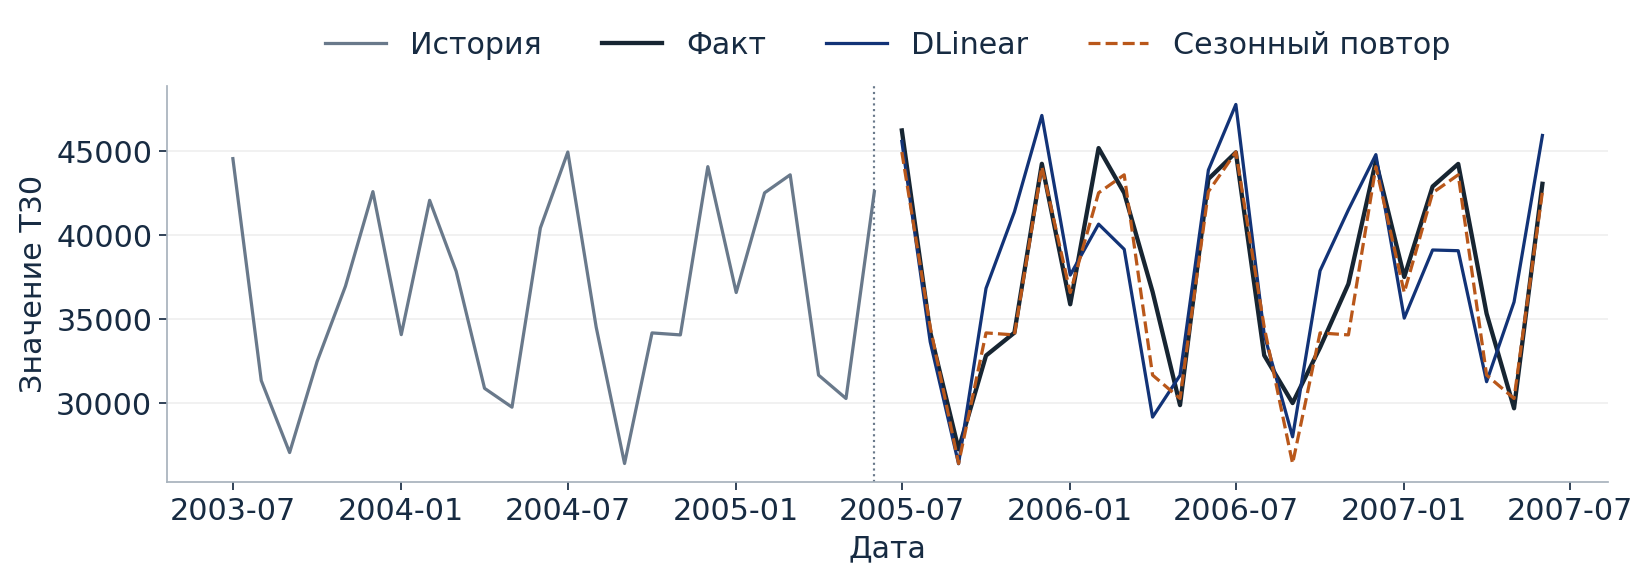

In [15]:
assert dlinear_prediction.index.equals(t30_test.index)
dl_seasonal_prediction = seasonal_t30
dl_seasonal_scale = t30_train.diff(12).abs().dropna().mean()
assert dl_seasonal_scale > 0
dl_compare = pd.DataFrame({"DLinear": dlinear_prediction, "Сезонный повтор": dl_seasonal_prediction})
dl_mae = dl_compare.sub(t30_test, axis="index").abs().mean()
dlinear_metrics = pd.DataFrame({"MAE": dl_mae, "MASE": dl_mae / dl_seasonal_scale})
display(dlinear_metrics.round(3))

dl_fig, dl_ax = plt.subplots(figsize=(10.5, 3.6), layout="constrained")
dl_ax.plot(t30_train.iloc[-24:], color="#69798B", label="История")
dl_ax.plot(t30_test, color="#172532", linewidth=2, label="Факт")
dl_ax.plot(dlinear_prediction, color="#123377", label="DLinear")
dl_ax.plot(dl_seasonal_prediction, "--", color="#B9571A", label="Сезонный повтор")
dl_ax.axvline(t30_train.index[-1], color="#69798B", linestyle=":", linewidth=1)
dl_ax.set(ylabel="Значение T30", xlabel="Дата")
dl_ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1))
dl_ax.grid(axis="y", alpha=0.2)
finish(dl_fig, "10_dlinear_forecast_T30.png")

На T30 повтор сезона дал MAE 1 285,4 и MASE 0,426. У DLinear средняя абсолютная ошибка за те же 24 месяца составила 3 157,4, а MASE — 1,047. Структура из двух обучаемых ветвей в этом выпуске уступила повторению прошлого года. Чтобы сравнить методы по всей коллекции, потребовался бы тот же расчёт на остальных рядах и датах выпуска.

<a id="bolt"></a>

## Chronos-Bolt. Прогноз T30 без дообучения

Исходный Chronos масштабирует значения и превращает их в токены. Здесь запускаем **Chronos-Bolt**. Его вход состоит из числовых патчей, а выход содержит квантили сразу для нескольких будущих месяцев.

Загрузим [Chronos-Bolt Small](https://huggingface.co/amazon/chronos-bolt-small) и по истории T30 получим медиану и границы интервала на 24 месяца.

Пример проверен с `chronos-forecasting==1.5.3` и `transformers==4.48.3`. Hugging Face использует свой кэш или один раз загружает около 191 МБ весов. Для запуска с локальной копией можно передать перед стартом Jupyter переменную `TS_CHRONOS_CHECKPOINT` с путём к папке с файлами `config.json` и `model.safetensors`.

In [16]:
from importlib.metadata import version

import torch
def _chronos_bolt_T30_functions():
    import argparse

    import hashlib

    import json

    import os

    from importlib.metadata import version

    from pathlib import Path

    import matplotlib.dates as mdates

    import matplotlib.pyplot as plt

    import numpy as np

    import pandas as pd

    MODEL_ID = "amazon/chronos-bolt-small"

    REVISION = "772f3d25d38aec6d914c8949dab4462e2d46f5d8"

    WEIGHTS_SHA256 = "06a6a19bbe74bc10a9cd193bd4bf2bf638ae07f7e0d51653ae7ab8ea968a21dd"

    ROOT = Path.cwd()

    DATA = data_path

    def verify_checkpoint(path):
        digest = hashlib.sha256()
        with (Path(path) / "model.safetensors").open("rb") as weights:
            for chunk in iter(lambda: weights.read(1024 * 1024), b""):
                digest.update(chunk)
        if digest.hexdigest() != WEIGHTS_SHA256:
            raise ValueError("Контрольная сумма весов отличается от официальной ревизии.")

    def plot_chronos_forecast(history, target, baseline, q10, median, q90, destination):
        """Plot a computed forecast using the same layout in Jupyter and on the slide."""
        with plt.rc_context():
            plt.rcdefaults()
            return _draw_forecast(history, target, baseline, q10, median, q90, destination)

    def _draw_forecast(history, target, baseline, q10, median, q90, destination):
        fig, ax = plt.subplots(figsize=(10.8, 4.1), layout="constrained")
        visible = history.iloc[-36:]
        ax.plot(visible.index, visible, color="#7C8996", label="История", lw=1.8)
        ax.fill_between(target.index, q10, q90, color="#2769AC", alpha=0.18,
                        label="Квантили 0,1–0,9")
        ax.plot(target.index, baseline, color="#147D74", ls="--", lw=2, label="Повтор сезона")
        ax.plot(target.index, median, color="#245DAD", lw=2.2, label="Медиана Chronos")
        ax.plot(target.index, target, color="#182736", lw=1.8, label="Факт")
        boundary = history.index[-1] + (target.index[0] - history.index[-1]) / 2
        ax.axvline(boundary, ls=":", lw=1.2, color="#6F7981")
        ax.xaxis.set_major_locator(mdates.YearLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
        ax.set_ylabel("Значение ряда T30", fontsize=14)
        ax.tick_params(labelsize=13)
        ax.grid(axis="y", alpha=0.17)
        ax.spines[["right", "top"]].set_visible(False)
        handles, labels = ax.get_legend_handles_labels()
        ax.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 1.01),
                  ncol=5, frameon=False, fontsize=12, columnspacing=1.1, handlelength=1.65)
        fig.savefig(destination, facecolor="white", dpi=155,
                    bbox_inches="tight", pad_inches=0.12)
        return fig

    return plot_chronos_forecast, verify_checkpoint

plot_chronos_forecast, verify_checkpoint = _chronos_bolt_T30_functions()
try:
    from chronos import BaseChronosPipeline
except ModuleNotFoundError as exc:
    if exc.name != "chronos":
        raise
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "chronos-forecasting==1.5.3", "transformers==4.48.3", "accelerate==1.3.0"])
    from chronos import BaseChronosPipeline
from huggingface_hub import snapshot_download

model_id = "amazon/chronos-bolt-small"
revision = "772f3d25d38aec6d914c8949dab4462e2d46f5d8"
local_checkpoint = os.environ.get("TS_CHRONOS_CHECKPOINT")
if local_checkpoint:
    checkpoint = Path(local_checkpoint).expanduser()
else:
    checkpoint = Path(snapshot_download(
        repo_id=model_id, revision=revision,
        allow_patterns=["config.json", "model.safetensors"],
    ))

verify_checkpoint(checkpoint)
bolt = BaseChronosPipeline.from_pretrained(
    checkpoint, device_map="cpu", torch_dtype=torch.float32, local_files_only=True
)
print(f"{model_id} · chronos-forecasting {version('chronos-forecasting')} · CPU")

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


amazon/chronos-bolt-small · chronos-forecasting 1.5.3 · CPU


### Что модель знает в момент прогноза

Вход заканчивается в июне 2005 года. Веса модели уже обучены. Из 306 известных месячных значений формируем один тензор. Фактические наблюдения с июля 2005 года понадобятся для оценки.

In [17]:
chronos_context = torch.tensor(t30_train.to_numpy(), dtype=torch.float32)
print(f"История: {len(chronos_context)} месяцев, с {t30_train.index[0]:%m.%Y} по {t30_train.index[-1]:%m.%Y}")
print(f"Прогноз: {H} месяцев, с {t30_test.index[0]:%m.%Y} по {t30_test.index[-1]:%m.%Y}")

История: 306 месяцев, с 01.1980 по 06.2005
Прогноз: 24 месяцев, с 07.2005 по 06.2007


### Что Chronos-Bolt получает на входе и возвращает на выходе

На схеме из лекции используем ту же историю T30, которая была известна в момент выпуска прогноза. После стандартизации модель делит последовательность на участки по 16 месяцев. Для 306 наблюдений требуются 20 участков с дополнением слева. На рисунке показаны последние три. Выходной слой Bolt-small рассчитывает девять уровней квантилей на 64 шага за один проход. В эксперименте берём первые 24 шага.

306 известных месяцев, 20 патчей, горизонт оценки 24 месяца.


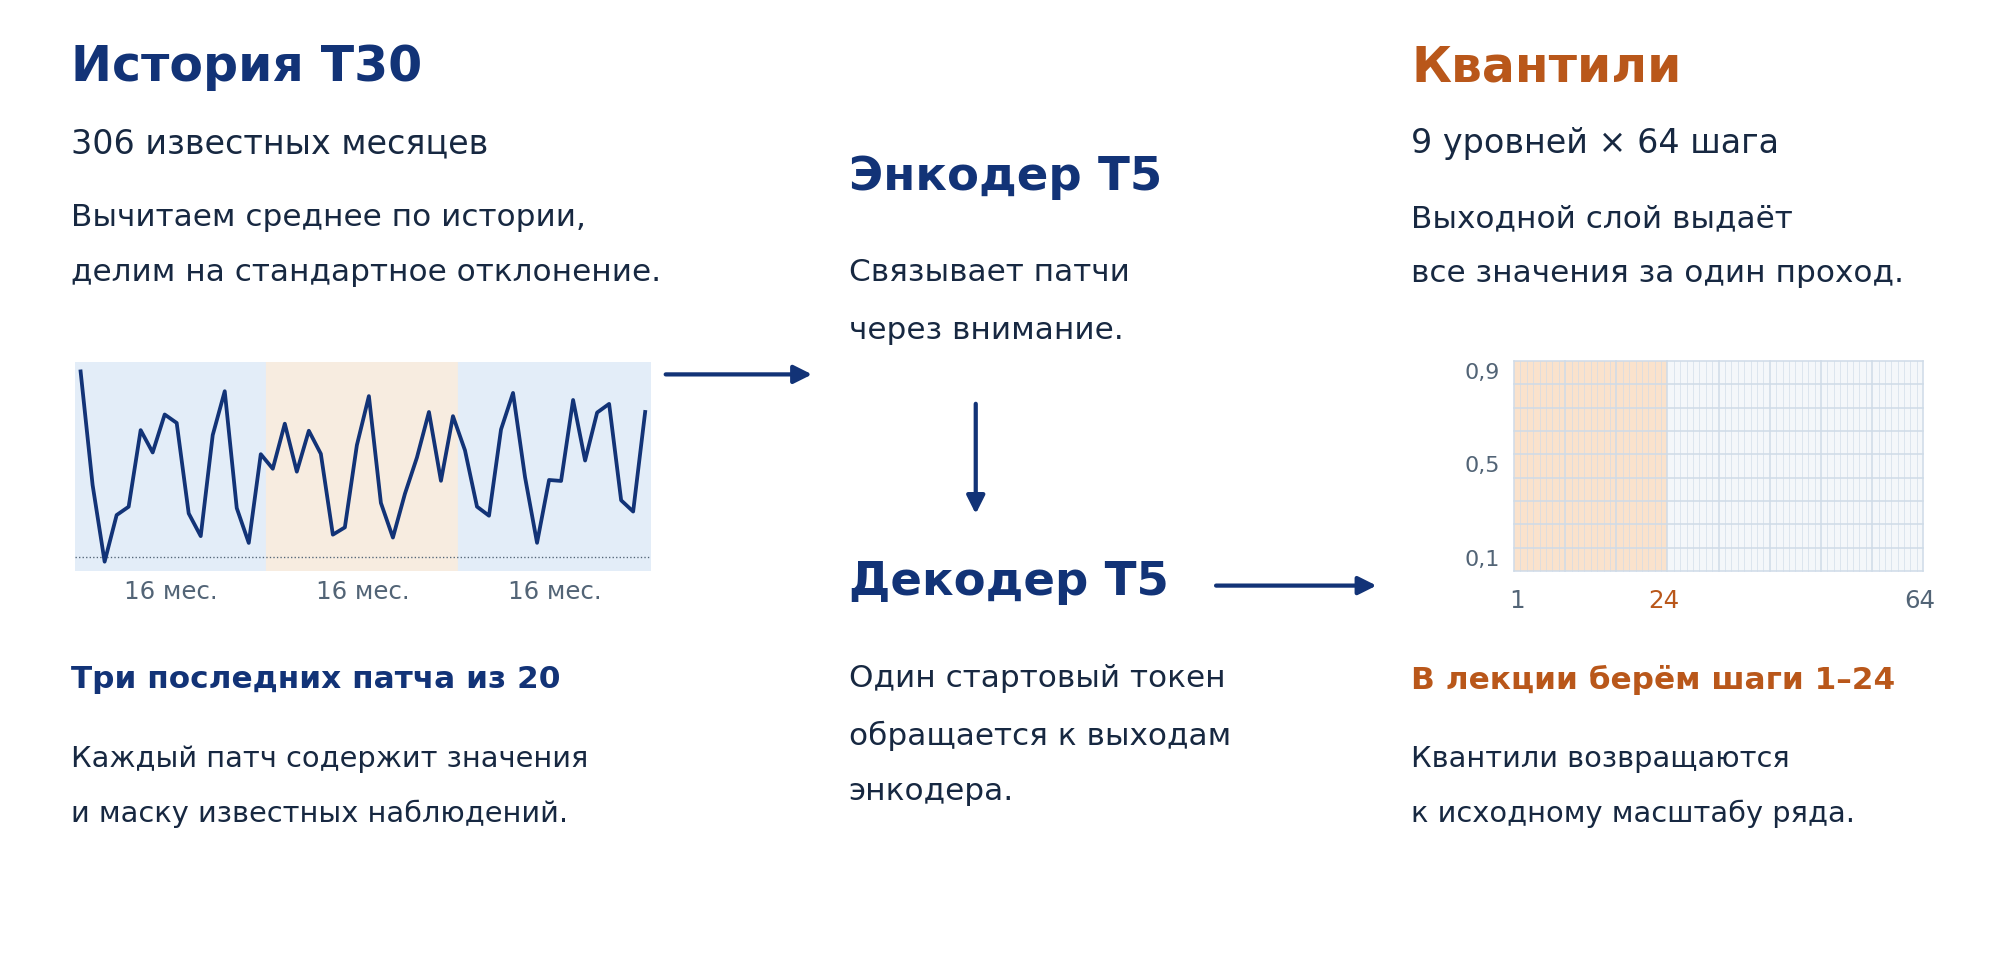

In [18]:
def _chronos_bolt_arch_functions():
    from pathlib import Path

    import numpy as np

    import matplotlib.pyplot as plt

    from matplotlib.patches import FancyArrowPatch, Rectangle

    ROOT = Path.cwd()

    DATA = data_path

    BLUE = "#123377"

    ORANGE = "#B9571A"

    TEXT = "#172841"

    MUTED = "#526476"

    GRID = "#CFDBE8"

    PLOT_STYLE = {"font.family": "DejaVu Sans", "mathtext.fontset": "dejavusans"}

    @plt.style.context(["default", PLOT_STYLE])
    def draw(t30_train=None, destination=ROOT / "chronos_bolt_arch.png"):
        """Схема Bolt-small для истории T30. Сохраняет PNG и возвращает его путь."""
        if t30_train is None:
            row = next(line for line in DATA.read_text(encoding="cp1252").splitlines()
                       if line.startswith("T30:"))
            train = np.fromstring(row.rsplit(":", 1)[1], sep=",")[:-24]
        else:
            train = np.asarray(t30_train, dtype=float)
        if train.ndim != 1 or len(train) < 48 or not np.isfinite(train).all() or train.std() == 0:
            raise ValueError("Для схемы нужны не менее 48 конечных значений T30 с ненулевым разбросом")
        observed = ((train - np.mean(train)) / np.std(train))[-48:]
        patch_count = (len(train) + 15) // 16
        fig = plt.figure(figsize=(12.6, 6), facecolor="white")
        main = fig.add_axes([0, 0, 1, 1])
        main.set(xlim=(0, 1), ylim=(0, 1))
        main.axis("off")

        def text(x, y, words, size=14, color=TEXT, **kwargs):
            main.text(x, y, words, fontsize=size, color=color, va="center", **kwargs)

        def arrow(x1, y1, x2, y2):
            main.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>",
                                           mutation_scale=17, linewidth=1.9, color=BLUE))

        text(0.035, 0.93, "История T30", 22, BLUE, weight="bold")
        text(0.035, 0.85, f"{len(train)} известных месяцев", 15)
        text(0.035, 0.773, "Вычитаем среднее по истории,", 14)
        text(0.035, 0.716, "делим на стандартное отклонение.", 14)
        patch_plot = fig.add_axes([0.037, 0.405, 0.286, 0.218])
        for i, bg in enumerate(["#E3EDF8", "#F7ECE0", "#E3EDF8"]):
            patch_plot.axvspan(i * 16 - 0.5, (i + 1) * 16 - 0.5, color=bg, zorder=0)
        patch_plot.plot(np.arange(48), observed, color=BLUE, linewidth=1.7)
        patch_plot.axhline(0, color=MUTED, lw=0.6, ls=":", zorder=0)
        patch_plot.set(xlim=(-0.5, 47.5), xticks=[7.5, 23.5, 39.5],
                       xticklabels=["16 мес.", "16 мес.", "16 мес."], yticks=[])
        patch_plot.tick_params(length=0, pad=4, colors=MUTED, labelsize=11)
        for spine in patch_plot.spines.values():
            spine.set_visible(False)
        text(0.035, 0.292, f"Три последних патча из {patch_count}", 14, BLUE, weight="bold")
        text(0.035, 0.209, "Каждый патч содержит значения", 13)
        text(0.035, 0.152, "и маску известных наблюдений.", 13)

        arrow(0.328, 0.61, 0.405, 0.61)
        text(0.421, 0.815, "Энкодер T5", 21, BLUE, weight="bold")
        text(0.421, 0.716, "Связывает патчи", 14)
        text(0.421, 0.656, "через внимание.", 14)
        arrow(0.484, 0.584, 0.484, 0.460)
        text(0.421, 0.393, "Декодер T5", 21, BLUE, weight="bold")
        text(0.421, 0.293, "Один стартовый токен", 14)
        text(0.421, 0.234, "обращается к выходам", 14)
        text(0.421, 0.175, "энкодера.", 14)

        arrow(0.601, 0.39, 0.685, 0.39)
        text(0.700, 0.93, "Квантили", 22, ORANGE, weight="bold")
        text(0.700, 0.85, "9 уровней × 64 шага", 15)
        text(0.700, 0.772, "Выходной слой выдаёт", 14)
        text(0.700, 0.715, "все значения за один проход.", 14)
        gx, gy, gw, gh = 0.751, 0.405, 0.203, 0.219
        main.add_patch(Rectangle((gx, gy), gw * 24/64, gh, color="#FAE2CC", lw=0))
        main.add_patch(Rectangle((gx + gw * 24/64, gy), gw * 40/64, gh,
                                 color="#F4F7FA", lw=0))
        for j in range(9 + 1):
            main.plot([gx, gx+gw], [gy+j*gh/9]*2, lw=0.7, color=GRID)
        for j in range(65):
            main.plot([gx+j*gw/64]*2, [gy, gy+gh],
                      lw=0.7 if j % 8 == 0 else 0.28, color=GRID)
        for q in [0.1, 0.5, 0.9]:
            text(gx-0.007, gy+gh*(q*10-0.5)/9, f"{q:.1f}".replace(".", ","),
                 10, MUTED, ha="right")
        for h in [1, 24, 64]:
            text(gx+gw*(h-0.5)/64, gy-0.031, str(h), 11,
                 ORANGE if h == 24 else MUTED, ha="center")
        text(0.700, 0.292, "В лекции берём шаги 1–24", 14, ORANGE, weight="bold")
        text(0.700, 0.209, "Квантили возвращаются", 13)
        text(0.700, 0.152, "к исходному масштабу ряда.", 13)
        path = Path(destination)
        try:
            path.parent.mkdir(parents=True, exist_ok=True)
            fig.savefig(path, dpi=160, facecolor="white")
        finally:
            plt.close(fig)
        return path

    return draw

draw_bolt_architecture = _chronos_bolt_arch_functions()

patch_length = 16
patch_count = (len(t30_train) + patch_length - 1) // patch_length
print(f"{len(t30_train)} известных месяцев, {patch_count} патчей, горизонт оценки {H} месяца.")
bolt_scheme_png = draw_bolt_architecture(t30_train, figure_output_dir / "chronos_bolt_arch.png")
display(Image(filename=str(bolt_scheme_png), width=900))

In [19]:
levels = [0.1, 0.5, 0.9]
with torch.inference_mode():
    quantiles, _ = bolt.predict_quantiles(
        context=chronos_context, prediction_length=H, quantile_levels=levels
    )
# Оси результата — ряд, горизонт, уровень квантиля.
assert tuple(quantiles.shape) == (1, H, len(levels))
chronos_q10, chronos_median, chronos_q90 = quantiles[0].cpu().numpy().T
chronos_forecast = pd.DataFrame({
    "Факт": t30_test.to_numpy(),
    "q0,1": chronos_q10, "Медиана": chronos_median, "q0,9": chronos_q90,
}, index=t30_test.index)
display(chronos_forecast.head(6).astype("float64").round(1))

Passing a tuple of `past_key_values` is deprecated and will be removed in Transformers v4.48.0. You should pass an instance of `EncoderDecoderCache` instead, e.g. `past_key_values=EncoderDecoderCache.from_legacy_cache(past_key_values)`.


,Факт,"q0,1",Медиана,"q0,9"
2005-07-01,46251.0,39431.9,43203.1,46775.8
2005-08-01,34231.0,32151.5,36007.8,40033.0
2005-09-01,27243.0,28277.5,32054.1,36272.0
2005-10-01,32830.0,34746.3,38880.4,43608.8
2005-11-01,34195.0,37034.6,41406.1,46564.1
2005-12-01,44261.0,37129.0,41918.2,47318.2


### Точность медианы и покрытие интервала

Сравним медиану с повторением последнего годового сезона по MAE и сезонной MASE. Масштаб для MASE посчитаем по истории T30 до отсечки. Для квантилей 0,1 и 0,9 отдельно измерим долю попавших между ними наблюдений и среднюю ширину диапазона в единицах исходного ряда.

In [20]:
chronos_baseline = seasonal_t30.to_numpy()
chronos_actual = t30_test.to_numpy()
chronos_scale = t30_train.diff(12).abs().mean()
chronos_mae = pd.Series({
    "Повтор сезона": np.mean(np.abs(chronos_actual - chronos_baseline)),
    "Медиана Chronos-Bolt": np.mean(np.abs(chronos_actual - chronos_median)),
}, name="MAE")
display(chronos_mae.to_frame().assign(MASE=chronos_mae / chronos_scale).round(3))

chronos_covered = (chronos_q10 <= chronos_actual) & (chronos_actual <= chronos_q90)
print(f"Покрытие: {chronos_covered.sum()} из {H} ({chronos_covered.mean():.1%}).")
print(f"Средняя ширина интервала: {np.mean(chronos_q90 - chronos_q10):.0f}.")

,MAE,MASE
Повтор сезона,1285.375,0.426
Медиана Chronos-Bolt,3316.151,1.100


Покрытие: 19 из 24 (79.2%).
Средняя ширина интервала: 11449.


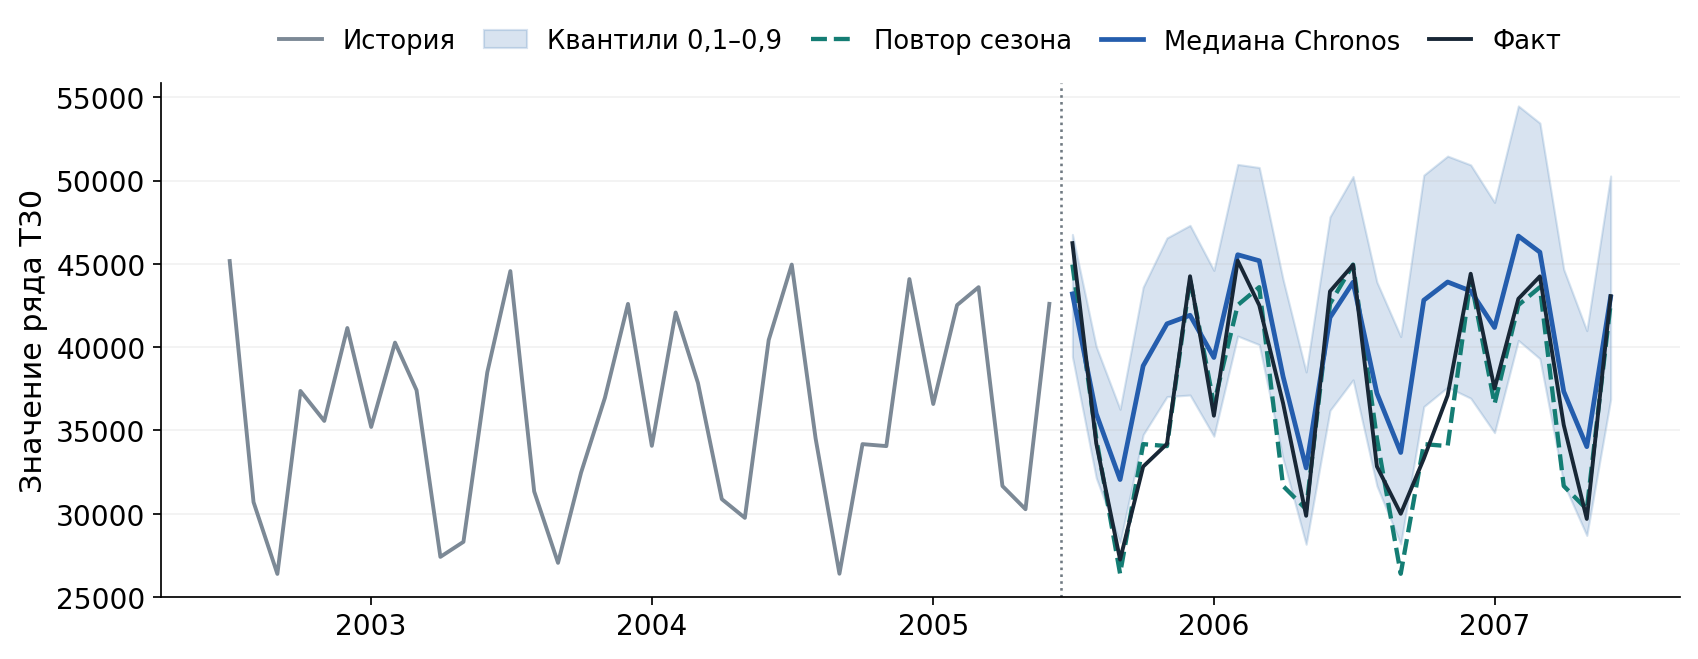

In [21]:
fig = plot_chronos_forecast(
    t30_train, t30_test, chronos_baseline,
    chronos_q10, chronos_median, chronos_q90,
    figure_output_dir / "09_chronos_bolt_T30.png",
)
plt.close(fig)
display(Image(filename=str(figure_output_dir / "09_chronos_bolt_T30.png"), width=900))

На T30 сезонный повтор точнее медианы Chronos-Bolt. Полоса показывает диапазон между двумя прогнозными квантилями для каждого месяца. Факт попадает в неё в 19 месяцах из 24. Чтобы судить о калибровке 80%-х интервалов, нужны повторные прогнозы на разных рядах и отсечках.

<a id="metrics"></a>

### Три прогноза на одни и те же 24 месяца

У всех моделей общая дата выпуска и общий тест с июля 2005 по июнь 2007. Для Chronos-Bolt берём медиану прогноза. Обозначим ошибку месяца через $e_h=y_h-\hat y_h$, а среднее по 24 тестовым месяцам через $\operatorname{mean}_h$.

| Метрики | Как читать |
|---|---|
| MAE, RMSE, MdAE | Среднее $\lvert e_h\rvert$, корень из среднего $e_h^2$ и медиана $\lvert e_h\rvert$. Все три в единицах ряда. RMSE сильнее реагирует на крупный промах, MdAE описывает типичную ошибку по центру распределения. |
| MAPE, WAPE | MAPE усредняет $100\,\lvert e_h\rvert/\lvert y_h\rvert$ с одинаковым весом месяцев. WAPE делит $100\sum_h\lvert e_h\rvert$ на $\sum_h\lvert y_h\rvert$. При положительных фактах это среднее процентных ошибок с весами, пропорциональными объёму месяца. |
| RelMAE, RelRMSE | Делим тестовую MAE или RMSE модели на соответствующую тестовую ошибку сезонного повтора. Значение $1$ соответствует базе, $0{,}8$ означает уменьшение ошибки на 20%. |
| MASE, RMSSE | Масштаб задаёт история до отсечки. MASE равна MAE, делённой на среднее $\lvert y_t-y_{t-12}\rvert$ на обучении. RMSSE равна RMSE, делённой на корень из среднего $(y_t-y_{t-12})^2$ на обучении. |

В колонке mSMAPE используем нижнюю границу знаменателя. Для каждого месяца делитель равен $d_h=\max(\lvert y_h\rvert+\lvert \hat y_h\rvert+\varepsilon,\;0{,}5+\varepsilon)/2$. Тогда $\mathrm{mSMAPE}=100\operatorname{mean}_h(\lvert e_h\rvert/d_h)$. Берём $\varepsilon=10^{-8}$ в единицах ряда. Для малых значений результат зависит от порога и единицы измерения.

MAPE не определена, если хотя бы один факт равен нулю. Близкий к нулю факт может дать огромный процент. Для WAPE нужен ненулевой суммарный объём. Для относительных ошибок нужна ненулевая ошибка базы, для MASE и RMSSE — ненулевое сезонное изменение в истории. При нулевом знаменателе в таблице будет пропуск. Так все модели оцениваются на одном и том же наборе месяцев.

[Hyndman и Athanasopoulos, оценка точности прогноза](https://otexts.com/fpp3/accuracy.html)

In [22]:
t30_predictions = pd.DataFrame({
    "Сезонный повтор": seasonal_t30, "DLinear": dlinear_prediction,
    "Медиана Chronos-Bolt": pd.Series(chronos_median, index=t30_test.index),
}, index=t30_test.index)
assert t30_predictions.index.equals(t30_test.index) and len(t30_test) == H
assert np.isfinite(t30_predictions.to_numpy()).all() and np.isfinite(t30_test.to_numpy()).all()

t30_errors = t30_predictions.rsub(t30_test, axis="index")  # факт минус прогноз
t30_abs = t30_errors.abs()
t30_mae = t30_abs.mean()
t30_rmse = (t30_errors.pow(2).mean()) ** 0.5
actual_size = t30_test.abs()
train_seasonal_delta = t30_train.diff(12).dropna()
seasonal_mae_scale = train_seasonal_delta.abs().mean()
seasonal_rmse_scale = (train_seasonal_delta.pow(2).mean()) ** 0.5

def scaled_error(numerator, denominator):
    return numerator / denominator if denominator > 0 else np.nan

# В MAPE нулевой факт делает неопределённой оценку по полному горизонту.
t30_mape = 100 * t30_abs.div(actual_size, axis="index").mean() if actual_size.gt(0).all() else np.nan
epsilon = 1e-8
symmetric_denominator = (t30_predictions.abs().add(actual_size, axis="index").clip(lower=0.5) + epsilon) / 2
t30_report = pd.DataFrame({
    "MAE": t30_mae,
    "RMSE": t30_rmse,
    "MdAE": t30_abs.median(),
    "MAPE, %": t30_mape,
    "WAPE, %": 100 * scaled_error(t30_abs.sum(), actual_size.sum()),
    "mSMAPE, %": 100 * (t30_abs / symmetric_denominator).mean(),
    "RelMAE": scaled_error(t30_mae, t30_mae["Сезонный повтор"]),
    "RelRMSE": scaled_error(t30_rmse, t30_rmse["Сезонный повтор"]),
    "MASE": scaled_error(t30_mae, seasonal_mae_scale),
    "RMSSE": scaled_error(t30_rmse, seasonal_rmse_scale),
})
display(t30_report.round(3))
t30_report.to_csv(output_dir / "Метрики_T30.csv", index_label="Модель")
monthly_report = t30_predictions.assign(Факт=t30_test, q10=chronos_q10, q90=chronos_q90)
monthly_report.to_csv(output_dir / "Прогнозы_T30.csv", index_label="Месяц")

,MAE,RMSE,MdAE,"MAPE, %","WAPE, %","mSMAPE, %",RelMAE,RelRMSE,MASE,RMSSE
Сезонный повтор,1285.375,1823.885,798.500,3.566,3.398,3.678,1.000,1.000,0.426,0.405
DLinear,3157.418,3753.820,2882.155,8.597,8.347,8.523,2.456,2.058,1.047,0.834
Медиана Chronos-Bolt,3316.151,4016.259,2960.839,9.508,8.766,8.903,2.580,2.202,1.100,0.892


У сезонного повтора MAE равна 1 285,38. У DLinear она в 2,46 раза больше, у медианы Bolt в 2,58 раза больше. Так читается RelMAE. У Bolt MAPE составляет 9,51%, WAPE — 8,77%. Оба числа получены из одних 24 ошибок: при переходе к WAPE месяцы с более крупным фактом получают больший вес. У DLinear RMSSE равна 0,834, а RelRMSE — 2,058. Историческое среднеквадратическое изменение T30 год к году было больше RMSE повторения сезона на этом тестовом отрезке. Вывод относится к этому ряду и этой дате выпуска.

### Откуда берётся ширина прогнозного интервала

В лекции показан отдельный учебный пример: случайное блуждание без дрейфа с независимыми нормальными приращениями и стандартным отклонением $\sigma=2$. Центральный прогноз сохраняет последнее наблюдение. На $h$ шагах дисперсия новых приращений складывается, поэтому стандартное отклонение ошибки равно $\sigma\sqrt{h}$. Посмотрим, насколько шире становится 95%-й интервал на 24-м шаге по сравнению с первым.

В этом примере границы вычисляются из известной модели. На реальных прогнозах Bolt можно посчитать, какая доля наблюдений попала между выбранными квантилями, и сопоставить её с шириной интервала.

,"Горизонт, месяцев",Стандартное отклонение ошибки,Половина ширины 95%-го интервала
0,1,2.0,3.92
1,24,9.8,19.20


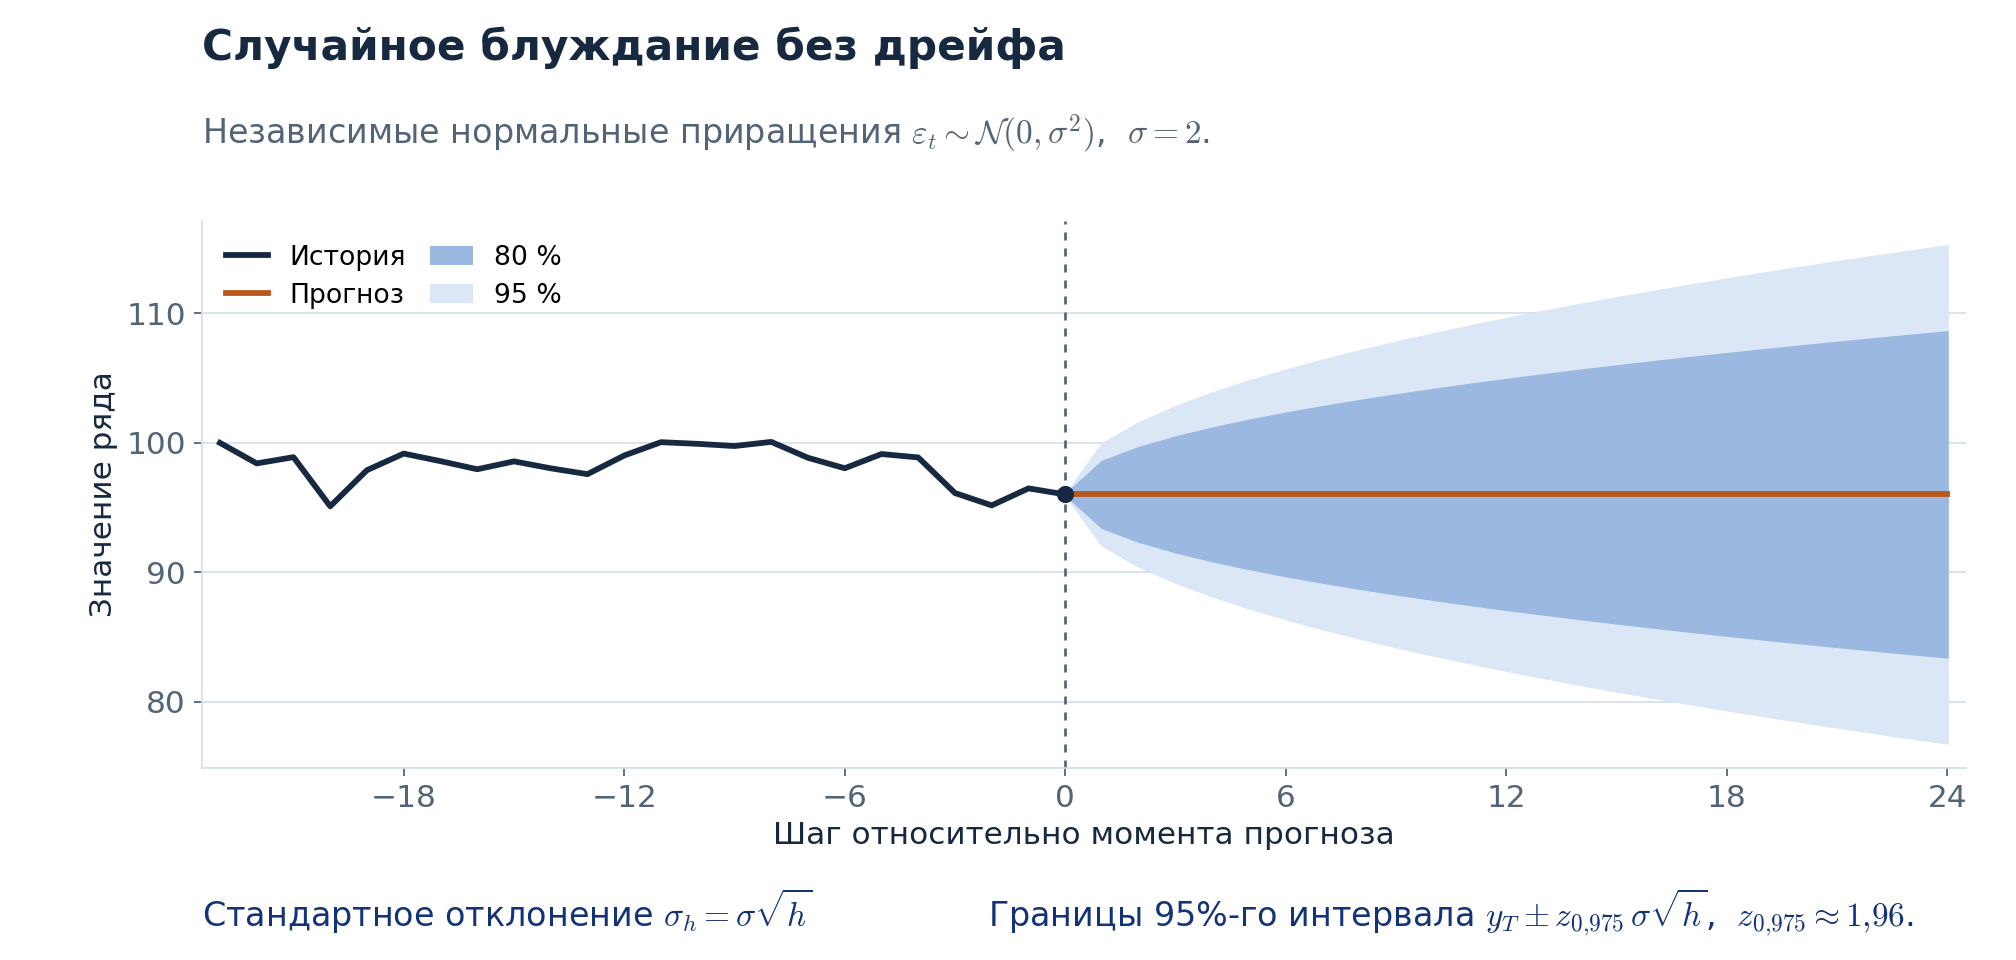

In [23]:
from statistics import NormalDist
def _concept_figures_functions():
    from pathlib import Path

    from statistics import NormalDist

    import numpy as np

    import matplotlib.pyplot as plt

    from matplotlib.patches import Patch

    OUT = Path.cwd()

    BLUE = "#123377"

    ORANGE = "#B9571A"

    INK = "#172841"

    MUTED = "#526476"

    GRID = "#D6DFEB"

    PLOT_STYLE = {
        "font.family": "DejaVu Sans",
        "font.size": 14,
        "mathtext.fontset": "cm",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.labelcolor": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "savefig.facecolor": "white",
    }

    def save_png(fig, destination):
        path = Path(destination)
        try:
            path.parent.mkdir(parents=True, exist_ok=True)
            fig.savefig(path, dpi=160)
        finally:
            plt.close(fig)
        return path

    def arrow(ax, start, end, color):
        ax.annotate("", xy=end, xytext=start, arrowprops={
            "arrowstyle": "-|>", "lw": 2.3, "color": color,
            "mutation_scale": 15, "shrinkA": 0, "shrinkB": 0,
        })

    @plt.style.context(["default", PLOT_STYLE])
    def draw_strategies(destination=OUT / "strategies.png"):
        """Сохранить схему и вернуть путь к PNG."""
        fig, ax = plt.subplots(figsize=(12.6, 6))
        fig.subplots_adjust(left=0.04, right=0.985, bottom=0.05, top=0.98)
        ax.set(xlim=(0, 12.5), ylim=(0, 6))
        ax.axis("off")
        xs = [0.8, 3.8, 7.25, 10.7]
        y = 4.35
        ax.text(0.05, 5.6, "Рекурсивный прогноз", color=BLUE,
                fontsize=20, weight="bold", va="center")
        ax.text(6.33, 5.60,
                r"$\widehat{y}_{T+h\mid T}=f\!\left(\widehat{y}_{T+h-1\mid T}\right)$",
                fontsize=21, color=BLUE, va="center")
        ax.text(0.05, 5.08,
                r"Одна модель принимает результат предыдущего шага. Начальная точка $\widehat{y}_{T\mid T}=y_T$.",
                color=MUTED, fontsize=15)
        ax.text(xs[0], y, r"$y_T$", ha="center", va="center", fontsize=24, color=INK)
        for h in range(1, 4):
            left, right = xs[h-1] + (0.43 if h == 1 else 0.78), xs[h] - 0.78
            arrow(ax, (left, y), (right, y), BLUE)
            ax.text((left+right)/2, y+0.11, r"$f$", ha="center", va="bottom",
                    color=BLUE, fontsize=19)
            ax.text(xs[h], y, rf"$\widehat{{y}}_{{T+{h}\mid T}}$", ha="center", va="center",
                    fontsize=24, color=BLUE)

        ax.plot([0.05, 12.0], [3.66, 3.66], lw=1.2, color=GRID)
        ax.text(0.05, 3.18, "Прямой прогноз", color=ORANGE,
                fontsize=20, weight="bold", va="center")
        ax.text(6.33, 3.18, r"$\widehat{y}_{T+h\mid T}=f_h(y_T)$",
                fontsize=21, color=ORANGE, va="center")
        ax.text(0.05, 2.65, "Каждая модель получает одно и то же последнее наблюдение.",
                color=MUTED, fontsize=15)
        bus_y, out_y = 2.0, 0.75
        ax.text(xs[0], bus_y, r"$y_T$", ha="center", va="center", fontsize=24, color=INK)
        ax.plot([xs[0]+0.43, xs[3]], [bus_y, bus_y], lw=2.3, color=ORANGE)
        for h, x in enumerate(xs[1:], 1):
            arrow(ax, (x, bus_y), (x, out_y+0.35), ORANGE)
            ax.text(x+0.14, (bus_y+out_y+0.35)/2, rf"$f_{h}$", color=ORANGE,
                    fontsize=19, va="center")
            ax.text(x, out_y, rf"$\widehat{{y}}_{{T+{h}\mid T}}$", color=ORANGE, ha="center",
                    va="center", fontsize=24)
        ax.text(0.05, 0.08, "На схеме у модели один лаг. В ноутбуке вход содержит 12 лагов.",
                color=MUTED, fontsize=13)
        return save_png(fig, destination)

    @plt.style.context(["default", PLOT_STYLE])
    def draw_intervals(destination=OUT / "intervals.png"):
        """Сохранить схему и вернуть путь к PNG."""
        fig, ax = plt.subplots(figsize=(12.6, 6))
        fig.subplots_adjust(left=0.10, right=0.975, bottom=0.20, top=0.77)
        rng = np.random.default_rng(2026)
        sigma = 2
        past = np.r_[100, 100+np.cumsum(rng.normal(0, sigma, 23))]
        h = np.arange(25)
        z80, z95 = [NormalDist().inv_cdf((1+p)/2) for p in (0.80, 0.95)]
        spread = sigma*np.sqrt(h)
        mid = past[-1]
        shades = ["#DBE7F6", "#9BB9E0"]
        ax.fill_between(h, mid-z95*spread, mid+z95*spread, color=shades[0], zorder=1)
        ax.fill_between(h, mid-z80*spread, mid+z80*spread, color=shades[1], zorder=2)
        ax.axvline(0, color=MUTED, linestyle=(0, (3, 3)), lw=1.2)
        ax.plot(np.arange(-23, 1), past, color=INK, lw=2.6)
        ax.plot(h, np.full(h.shape, mid), color=ORANGE, lw=2.6)
        ax.scatter([0], [mid], s=45, color=INK, zorder=4)
        ax.set(xlim=(-23.5, 24.5), xlabel="Шаг относительно момента прогноза",
               ylabel="Значение ряда", xticks=[-18,-12,-6,0,6,12,18,24])
        ax.grid(axis="y", color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
        for name in ("bottom", "left"):
            ax.spines[name].set_color(GRID)
        fig.text(0.10, 0.95, "Случайное блуждание без дрейфа", color=INK, weight="bold",
                 fontsize=19, va="center")
        fig.text(0.10, 0.86,
                 r"Независимые нормальные приращения $\varepsilon_t\sim\mathcal{N}(0,\sigma^2)$,  $\sigma=2$.",
                 color=MUTED, fontsize=15, va="center")
        handles = [
            plt.Line2D([], [], color=INK, lw=2.6, label="История"),
            plt.Line2D([], [], color=ORANGE, lw=2.6, label="Прогноз"),
            Patch(facecolor=shades[1], label="80 %"),
            Patch(facecolor=shades[0], label="95 %"),
        ]
        ax.legend(handles=handles, loc="upper left", frameon=False, ncol=2, fontsize=12,
                  labelspacing=0.45, columnspacing=0.9, handlelength=1.6)
        fig.text(0.10, 0.035, r"Стандартное отклонение $\sigma_h=\sigma\sqrt{h}$",
                 color=BLUE, fontsize=15)
        fig.text(0.49, 0.035,
                 r"Границы 95%-го интервала $y_T\pm z_{0{,}975}\,\sigma\sqrt{h}$,  $z_{0{,}975}\approx1{,}96$.",
                 color=BLUE, fontsize=15)
        return save_png(fig, destination)

    return draw_intervals, draw_strategies

draw_intervals, draw_strategies = _concept_figures_functions()

steps = np.array([1, H])
std_forecast = 2 * np.sqrt(steps)
half_width = NormalDist().inv_cdf(0.975) * std_forecast
display(pd.DataFrame({
    "Горизонт, месяцев": steps,
    "Стандартное отклонение ошибки": std_forecast,
    "Половина ширины 95%-го интервала": half_width,
}).round(2))
intervals_png = draw_intervals(figure_output_dir / "intervals.png")
display(Image(filename=str(intervals_png), width=900))

<a id="panel"></a>

## Сезонный прогноз и две Ridge на 366 рядах

Теперь возвращаемся к эксперименту лекции с тремя выпусками прогноза для каждого из 366 рядов. Здесь участники сравнения — сезонный повтор и две стратегии Ridge. У всех одна и та же длина тестового окна и доступная к моменту выпуска история. DLinear и Bolt выше запускались только на T30.

## Три стратегии при одной истории

**Повтор сезона.** Берём последние 12 наблюдений и повторяем их дважды.

**Рекурсивная Ridge.** Обучаем одну линейную регрессию предсказывать следующий месяц по предыдущим 12. После первого прогноза сдвигаем окно и подставляем в него собственное предсказание. За 24 шага ошибка может накопиться.

**Прямые Ridge.** Для каждого горизонта от 1 до 24 обучаем отдельную регрессию на тех же 12 лагах. При прогнозе все модели видят последние 12 фактов. Чем дальше целевой месяц от конца окна, тем меньше учебных пар остаётся.

Каждый ряд обрабатывается отдельно. Из истории обучения вычитаем среднее и делим на стандартное отклонение. Коэффициент регуляризации равен 1. Свободный член не штрафуется. Масштаб, среднее и параметры моделей заново вычисляются на каждой отсечке. Для постоянной истории используем последнюю величину.

In [24]:
def ridge_fit(X, y, alpha):
    # Центрирование оставляет свободный член вне штрафа.
    x_mean, y_mean = X.mean(axis=0), y.mean()
    centered = X - x_mean
    gram = centered.T @ centered
    weights = np.linalg.solve(gram + alpha * np.eye(X.shape[1]), centered.T @ (y - y_mean))
    intercept = y_mean - x_mean @ weights
    return weights, intercept


def make_forecasts(history, horizon=H, lag=L, alpha=ALPHA, season_length=12):
    y = np.asarray(history, dtype=float)
    if len(y) < max(lag + horizon, season_length):
        raise ValueError("Недостаточно истории для всех прямых моделей")
    repeated = np.resize(y[-season_length:], horizon)
    scale = y.std()
    if scale == 0:
        return {model: np.full(horizon, y[-1]) for model in models}

    z = (y - y.mean()) / scale
    windows = sliding_window_view(z, lag)
    weights, intercept = ridge_fit(windows[:-1], z[lag:], alpha)
    last = windows[-1].copy()
    recursive = []
    for _ in range(horizon):
        prediction = last @ weights + intercept
        recursive.append(prediction)
        last = np.r_[last[1:], prediction]

    direct = []
    for step in range(1, horizon + 1):
        weights, intercept = ridge_fit(windows[:-step], z[lag + step - 1:], alpha)
        direct.append(windows[-1] @ weights + intercept)
    return {"seasonal": repeated,
            "recursive": np.asarray(recursive) * scale + y.mean(),
            "direct": np.asarray(direct) * scale + y.mean()}

### Какие значения поступают на второй шаг

На схеме из лекции в момент $T$ известно значение $y_T$. Рекурсивная модель $f$ строит прогноз на один шаг и подставляет собственный результат на следующем. Прямые модели $f_1,f_2,f_3$ получают одно и то же наблюдение и отвечают каждая за свой горизонт. На схеме один лаг. У обеих моделей Ridge в этом опыте входное окно содержит 12 месяцев.

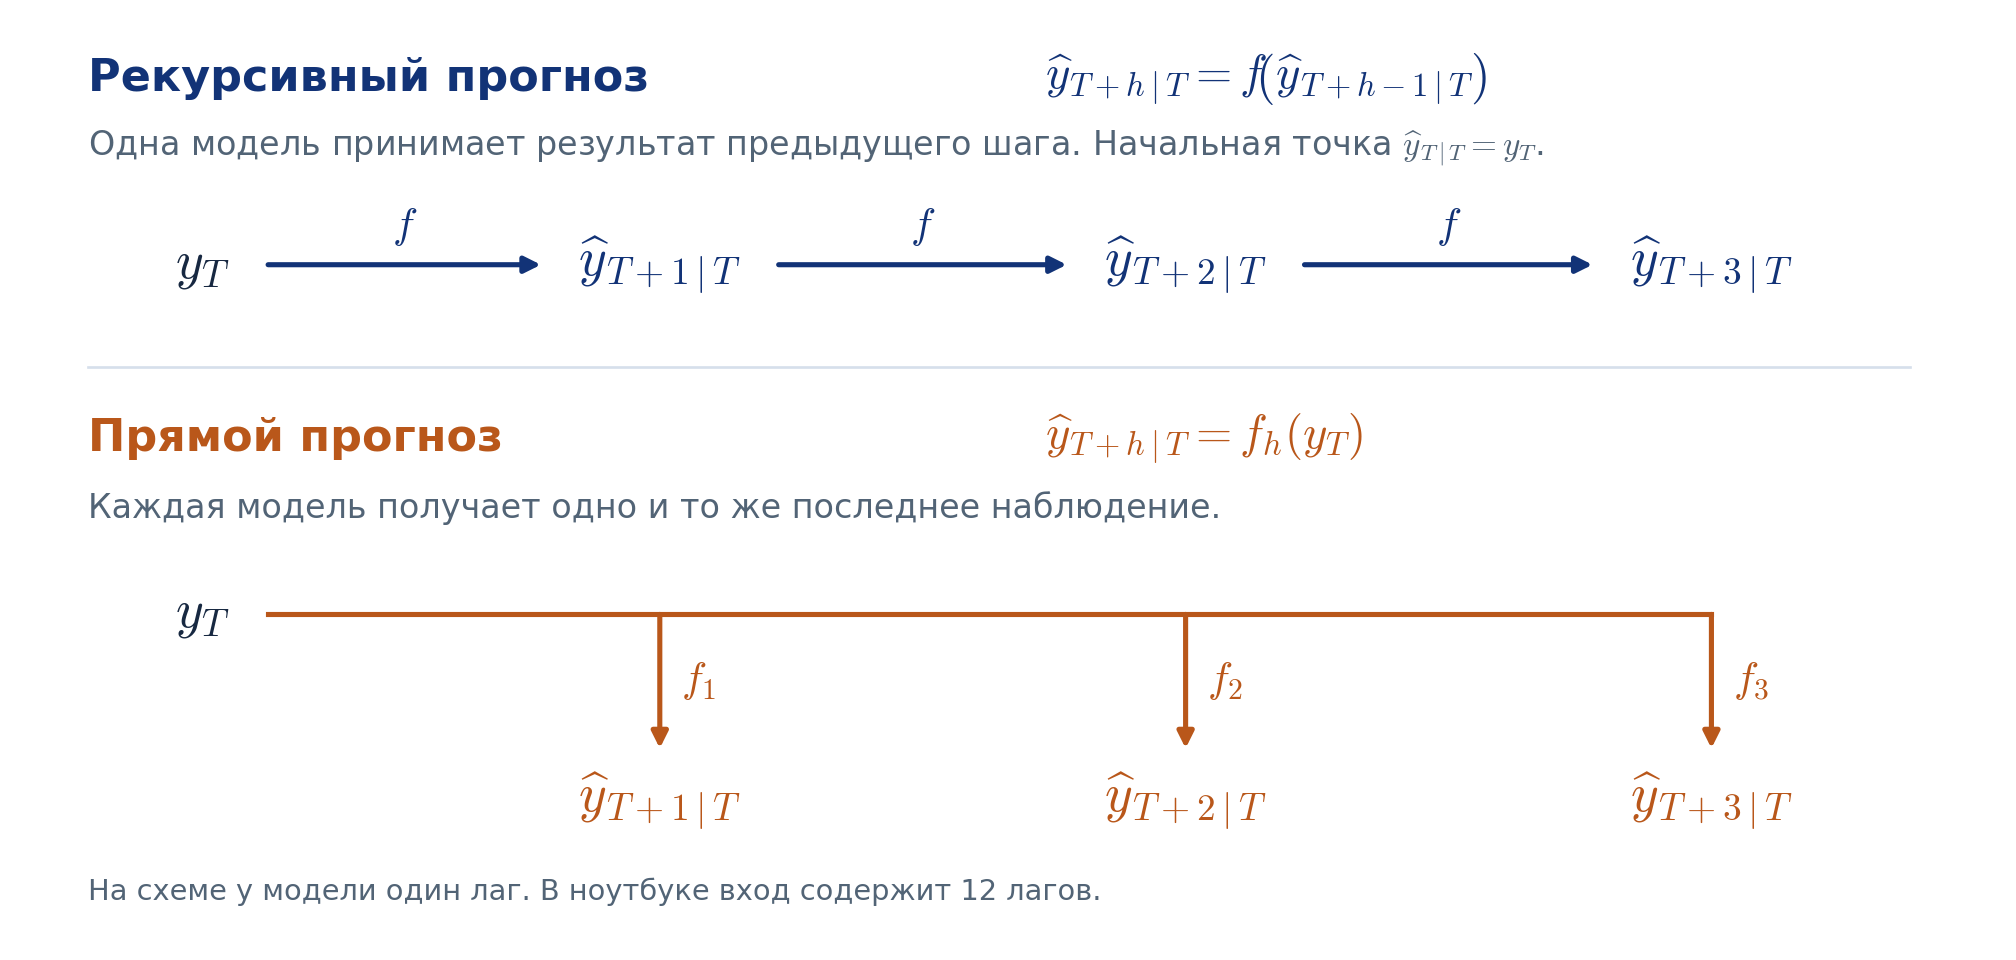

In [25]:


strategies_png = draw_strategies(figure_output_dir / "strategies.png")
display(Image(filename=str(strategies_png), width=900))

## Один прогноз и три даты его запуска

На каждой отсечке все 24 месяца предсказываются сразу. Для каждой серии вырезаем последние 48, 36 или 24 месяца и обучаемся только на предшествующей истории. На рисунке ноль означает последний доступный месяц всего ряда. Соседние тестовые интервалы перекрываются на 12 месяцев. Эти срезы показывают чувствительность результата к выбору даты, независимыми экспериментами они не являются.

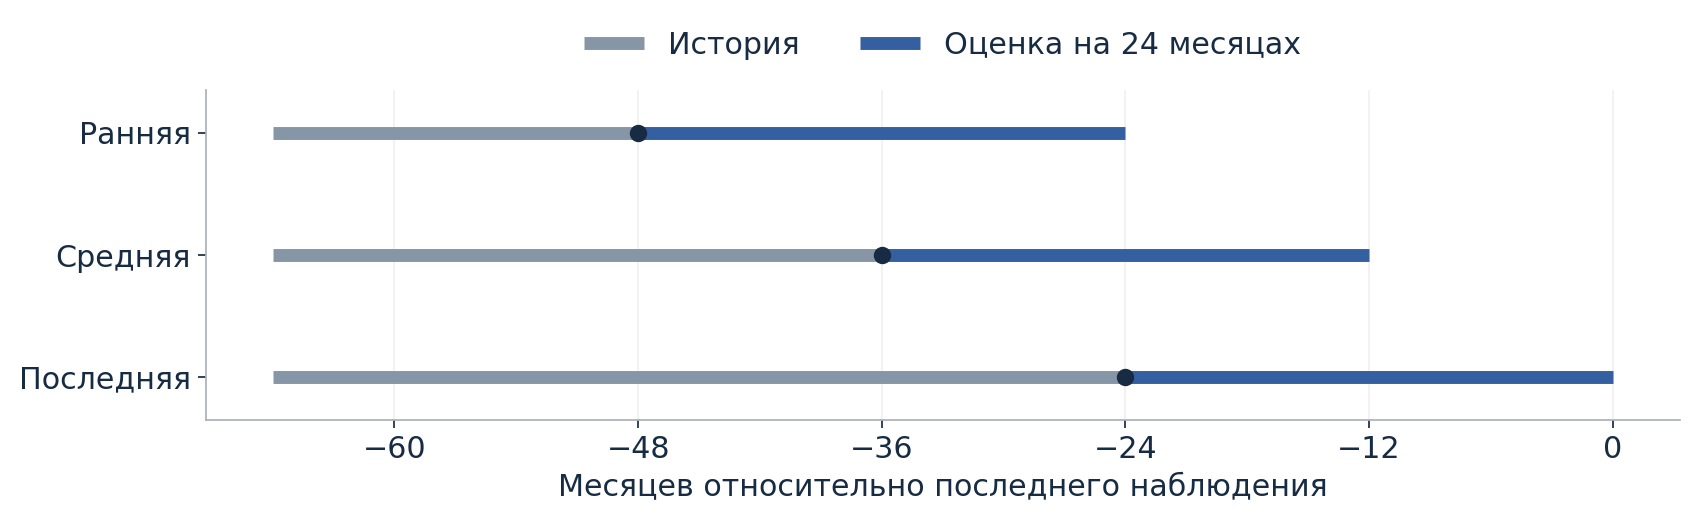

In [26]:
offsets = (48, 36, 24)
assert min(lengths) - max(offsets) >= L + H
fig, ax = plt.subplots(figsize=(10.8, 3.2), layout="constrained")
for i, offset in enumerate(offsets):
    ax.plot([-66, -offset], [i, i], lw=6, color="#8696A7", solid_capstyle="butt",
            label="История" if i == 0 else None)
    ax.plot([-offset, -offset + H], [i, i], lw=6, color=colors["direct"], solid_capstyle="butt",
            label="Оценка на 24 месяцах" if i == 0 else None)
    ax.scatter(-offset, i, color=ink, s=50, zorder=3)
ax.set(yticks=range(3), yticklabels=["Ранняя", "Средняя", "Последняя"],
       xticks=[-60,-48,-36,-24,-12,0], xlabel="Месяцев относительно последнего наблюдения")
ax.set_ylim(2.35, -0.35)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=2)
ax.grid(axis="x", alpha=0.18)
finish(fig, "03_backtest_origins.png")

## Как сравнить ошибки разных рядов

MAE измеряет средний модуль ошибки за 24 месяца в единицах исходного ряда. Для объединения рядов используем сезонный MASE. Для каждого ряда делим MAE модели на среднюю величину $|y_t-y_{t-12}|$ на истории **до этой отсечки**. Полученные масштабы положительны у всех рядов. При усреднении каждый ряд получает одинаковый вес.

MASE меньше 1 означает, что ошибка меньше среднего годового изменения **на обучении**. Чтобы установить, обошла ли модель сезонный прогноз **на тесте**, сравниваем их тестовые ошибки напрямую.

In [27]:
records = []
for offset in offsets:
    for name, y in series.items():
        stop = len(y) - offset
        train = y.iloc[:stop].to_numpy()
        actual = y.iloc[stop:stop + H].to_numpy()
        seasonal_scale = np.abs(train[12:] - train[:-12]).mean()
        assert seasonal_scale > 0 and len(actual) == H
        predicted = make_forecasts(train)
        assert np.isclose(predicted["recursive"][0], predicted["direct"][0])
        for model, forecast in predicted.items():
            absolute_errors = np.abs(actual - forecast)
            records.append((offset, name, model, absolute_errors.mean(), absolute_errors / seasonal_scale))

scores = pd.DataFrame(records, columns=["offset", "series", "model", "MAE", "scaled_errors"])
scores["MASE"] = [values.mean() for values in scores.scaled_errors]
summary = scores.pivot_table(values="MASE", index="offset", columns="model", aggfunc="mean").loc[list(offsets), list(models)]
display(summary.rename(columns=labels, index={48:"Ранняя", 36:"Средняя", 24:"Последняя"}).round(3))

model,Повтор сезона,Рекурсивная Ridge,Прямые Ridge
offset,,,
Ранняя,1.995,2.040,2.081
Средняя,1.808,1.864,1.823
Последняя,1.631,1.729,1.694


## Почему у разных рядов выигрывают разные модели

Следующие два ряда выбраны после расчёта, чтобы показать два разных случая. Прогноз начинается сразу после вертикальной черты. Пунктир повторяет последний наблюдавшийся сезон, две другие цветные линии показывают регрессионные прогнозы. У T30 сезонный повтор точнее обеих регрессий. У T47 меньшую ошибку дают отдельные модели для каждого горизонта.

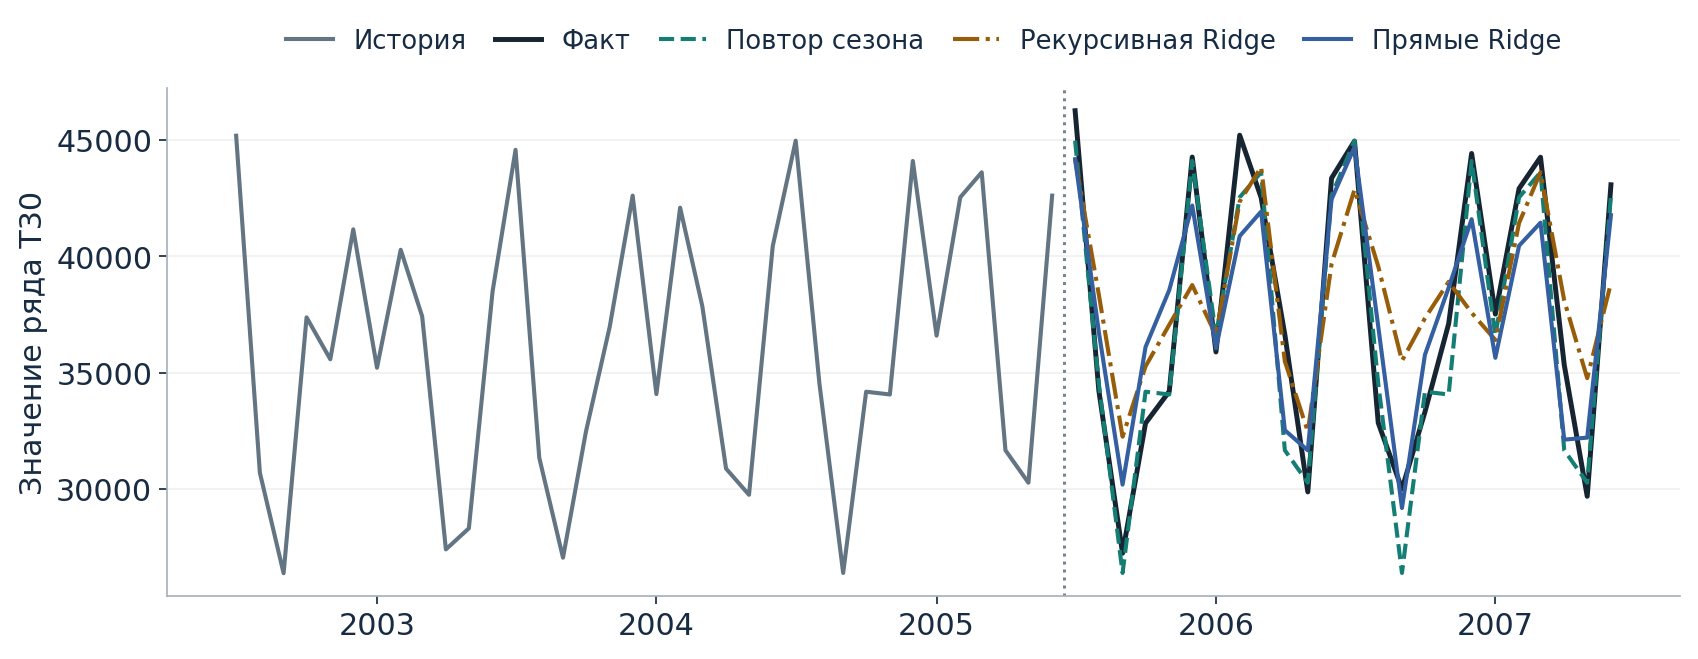

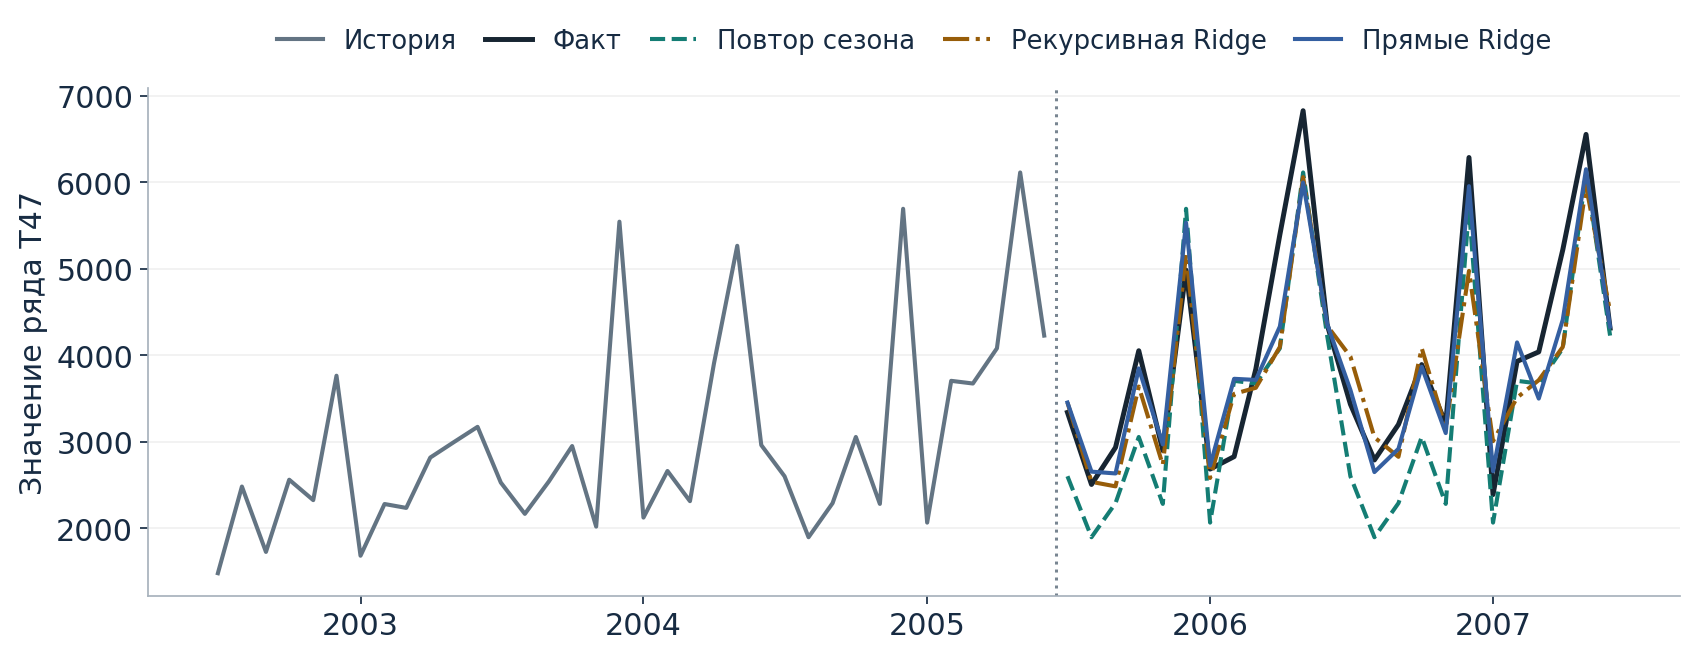

model,Повтор сезона,Рекурсивная Ridge,Прямые Ridge
series,,,
T30,0.426,1.058,0.765
T47,1.928,1.289,0.940


In [28]:
def plot_example(name):
    y = series[name]
    history, target = y.iloc[:-H], y.iloc[-H:]
    predictions = make_forecasts(history)
    fig, ax = plt.subplots(figsize=(10.8, 4.1), layout="constrained")
    visible = history.iloc[-36:]
    ax.plot(visible.index, visible.values, color="#637483", linewidth=1.9, label="История")
    ax.plot(target.index, target, color="#172532", linewidth=2.3, label="Факт")
    for model in models:
        ax.plot(target.index, predictions[model], color=colors[model], linestyle=styles[model],
                linewidth=1.9, label=labels[model])
    boundary = history.index[-1] + (target.index[0] - history.index[-1]) / 2
    ax.axvline(boundary, color="#788591", ls=":", linewidth=1.4)
    ax.set_ylabel(f"Значение ряда {name}")
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.grid(axis="y", alpha=0.18)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=5,
              handlelength=1.8, columnspacing=1.1, fontsize=12)
    finish(fig, f"{'04' if name == 'T30' else '05'}_forecast_{name}.png")

plot_example("T30")
plot_example("T47")
example_scores = scores.query("offset == 24 and series in ['T30', 'T47']").pivot(index="series", columns="model", values="MASE")
display(example_scores.loc[:,list(models)].rename(columns=labels).round(3))

## Где на горизонте растёт ошибка

Фиксируем последнюю отсечку. В каждом месяце усредняем абсолютные ошибки по всем 366 рядам после деления на исторический сезонный масштаб соответствующего ряда. В первом месяце две Ridge совпадают: их обучающие пары и признаки для этого шага одинаковы.

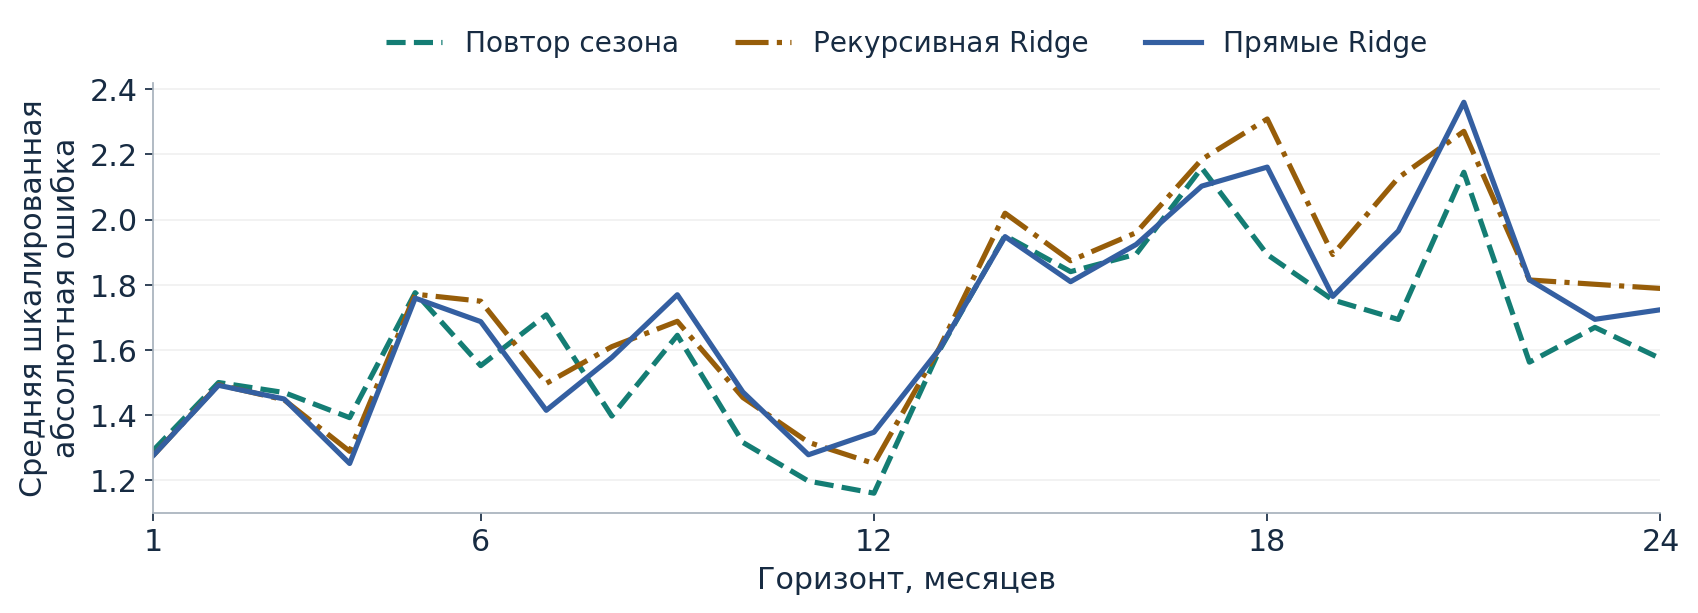

In [29]:
last_scores = scores.loc[scores.offset.eq(24)]
curves = {model: np.stack(last_scores.loc[last_scores.model.eq(model), "scaled_errors"]).mean(axis=0)
          for model in models}
fig, ax = plt.subplots(figsize=(10.8, 3.8), layout="constrained")
for model, values in curves.items():
    ax.plot(np.arange(1, H+1), values, color=colors[model], ls=styles[model],
            linewidth=2.4, label=labels[model])
ax.set(xlabel="Горизонт, месяцев", ylabel="Средняя шкалированная\nабсолютная ошибка",
       xticks=[1, 6, 12, 18, 24], xlim=(1, H))
ax.grid(axis="y", alpha=0.18)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1), ncol=3, fontsize=13)
finish(fig, "06_error_horizon.png")

## Как вывод зависит от отсечки и способа сравнения

Первый рисунок показывает средний сезонный MASE моделей по 366 рядам для каждой отсечки. Второй отвечает на другой вопрос: на скольких рядах модель получила минимальную MAE за 24 месяца последней оценки? Одно крупное поражение заметно меняет среднюю ошибку, но оно учитывается только как одно поражение при подсчёте побед.

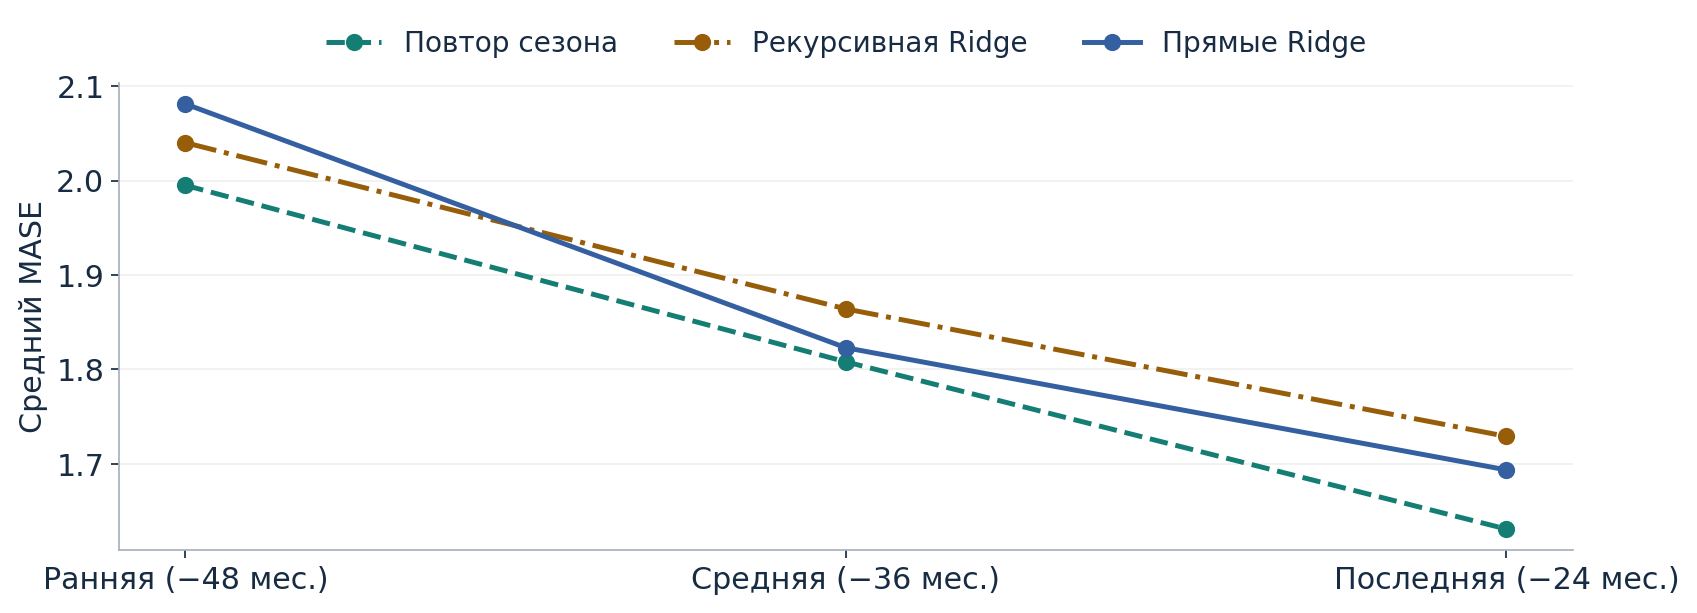

Рядов с одинаковой лучшей ошибкой: 0.


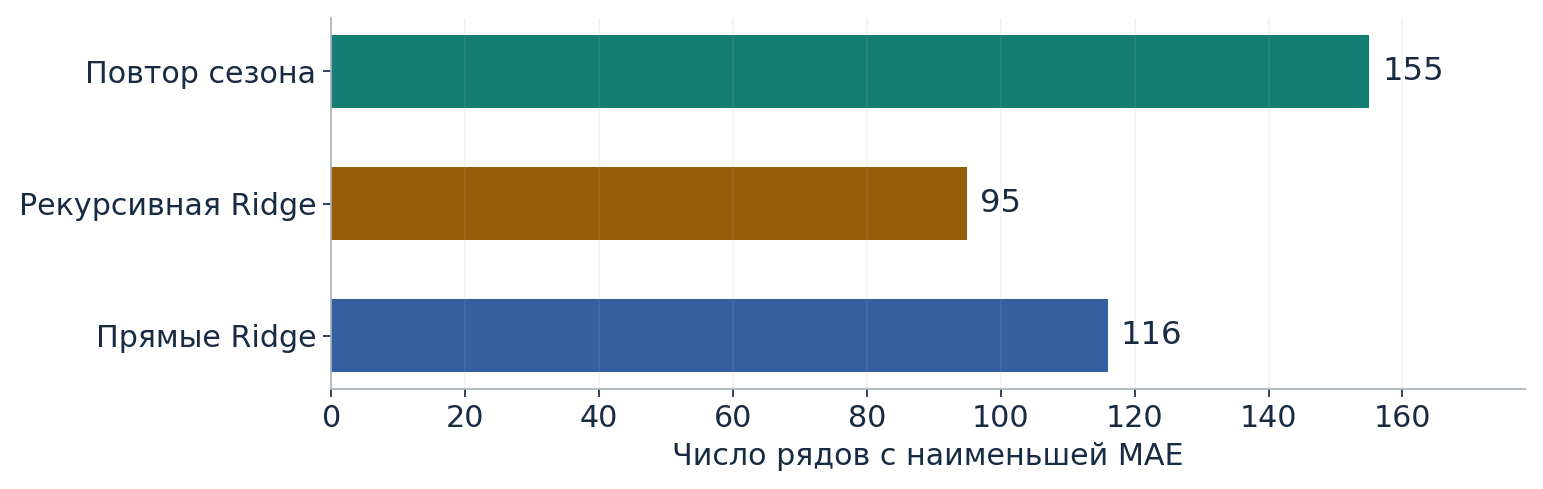

In [30]:
fig, ax = plt.subplots(figsize=(10.8, 3.8), layout="constrained")
for model in models:
    ax.plot(range(3), summary[model], color=colors[model], ls=styles[model], linewidth=2.3,
            marker="o", ms=7, label=labels[model])
ax.set(xticks=range(3), xticklabels=["Ранняя (−48 мес.)", "Средняя (−36 мес.)", "Последняя (−24 мес.)"],
       ylabel="Средний MASE")
ax.grid(axis="y", alpha=0.18)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1), ncol=3, fontsize=13)
finish(fig, "07_backtest_mase.png")

wide = last_scores.pivot(index="series", columns="model", values="MAE").loc[:, list(models)]
is_best = np.isclose(wide, wide.min(axis=1).to_numpy()[:,None], rtol=1e-10, atol=1e-12)
tie_count = int((is_best.sum(axis=1) > 1).sum())
wins = wide.idxmin(axis=1)[is_best.sum(axis=1) == 1].value_counts().reindex(models, fill_value=0)
print(f"Рядов с одинаковой лучшей ошибкой: {tie_count}.")
fig, ax = plt.subplots(figsize=(9.8, 3.0), layout="constrained")
bars = ax.barh([labels[k] for k in models], wins, color=[colors[k] for k in models], height=0.55)
ax.invert_yaxis()
ax.set(xlabel="Число рядов с наименьшей MAE", xlim=(0, max(wins)*1.15))
ax.bar_label(bars, padding=6, fontsize=15)
ax.grid(axis="x", alpha=0.15)
finish(fig, "08_wins.png")